# Quantium Retail Customer Analytics
### Customer & product insight, and a store-layout trial evaluation, for the Category Manager (chips & savoury snacks)

*Data: 12 months of loyalty-card transactions (Jul 2018 - Jun 2019) across 271 stores, plus a customer profile file.*

---
## Executive summary (the answer first)

**1. The growth opportunity is frequency, not new shoppers.** Sales are flat at about $150K a month. Families (young + older) are 26% of customers but generate 35% of chip sales because each buys roughly 9 packs a year, about double the 4.5 of young singles/couples. The single biggest customer group, **Mainstream Young Singles/Couples (7,930 customers)**, buys least often yet pays the most per pack ($4.06 vs $3.69, a statistically clear gap). One extra pack per customer in that group is worth about **$32K, or 1.8% of total sales**.

**2. The new store layout looks promising but is *not yet proven*.** All three trial stores beat their matched control stores (sales +11% to +28%, customers +7% to +26%), but no store beat normal month-to-month variation in all three trial months, none passes the whole-period significance test (p = 0.15 - 0.32 for sales), and the effect faded by April in two of three stores. A placebo test shows that 23% of untouched stores also show at least one "significant" month by chance. **Recommendation: do not roll out chain-wide on this evidence; run a larger, longer, pre-registered second trial.**

**3. What to do now:** (a) target Mainstream young singles/couples with premium-brand sharing packs (Kettle, Doritos, Tyrrells and 270-380g bags) to lift frequency; (b) protect the family base with value/large-pack availability; (c) re-test the layout in more stores for 6+ months, with store 86 as the most credible early candidate.

---
## Table of contents
0. [Setup & assumptions](#0)
1. [Stage 1: Know the data](#1) - quality checks, cleaning log, merge, KPIs, segments, products
2. [Stage 2: Did the new layout work?](#2) - control stores, significance tests, robustness
3. [Stage 3: Conclusions, recommendations & limitations](#3)

<a id="0"></a>
## 0. Setup & assumptions

**Facts** come straight from the two supplied files. **Assumptions** are listed here because they are not in the data and the reader should challenge them:

| # | Assumption | Why it matters |
|---|---|---|
| A1 | The trialled stores are **77, 86 and 88**; the trial ran **Feb-Apr 2019** (pre-trial = Jul 2018-Jan 2019). *These come from the project brief, not from the data files.* | Everything in Stage 2 depends on it. Change `TRIAL_STORES` and the date constants at the top of Section 2 to re-run. |
| A2 | "Chips" category = chips & savoury snacks; salsa **dips** are out of scope. | Excluded in the cleaning step; sensitivity is logged. |
| A3 | Sales = revenue (no margin/cost data supplied). | Recommendations are about revenue, not profit. |
| A4 | A customer = a loyalty card; a transaction = a unique `TXN_ID`. | Non-loyalty shoppers are invisible. |

In [1]:
import warnings, json, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 30)

# ---- Paths (notebook lives in /notebooks) ----
RAW, PROC, IMG = Path("../data/raw"), Path("../data/processed"), Path("../images")
for p in (PROC, IMG):
    p.mkdir(parents=True, exist_ok=True)

# ---- Corporate palette & chart defaults ----
NAVY, TEAL, AMBER, RED, GREY, LIGHT = "#1B2A41", "#0F8B8D", "#F2A541", "#C8553D", "#8D99AE", "#E9EDF2"
PREMIUM_PAL = {"Budget": GREY, "Mainstream": TEAL, "Premium": NAVY}
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 110, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.edgecolor": "#CBD2DC", "grid.color": "#E6EAF0",
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})

def save(fig, name):
    fig.savefig(IMG / f"{name}.png", dpi=160, bbox_inches="tight", facecolor="white")

dollar = mtick.FuncFormatter(lambda x, _: f"${x:,.0f}")
RESULTS = {}          # collects verified numbers for the report, deck and workbook

<a id="1"></a>
# 1. Stage 1: Get to know the data
## 1.1 Load the data
Two files: a transaction log (one row per product line) and a customer profile (lifestage and premium tier per loyalty card). No existing notebook was supplied, so this is built from the raw files.

In [2]:
tx = pd.read_excel(RAW / "QVI_transaction_data.xlsx")
cust = pd.read_csv(RAW / "QVI_purchase_behaviour.csv")

# Excel can store dates as serial numbers; convert only if that happened here
if pd.api.types.is_numeric_dtype(tx["DATE"]):
    tx["DATE"] = pd.to_datetime("1899-12-30") + pd.to_timedelta(tx["DATE"], unit="D")

print(f"Transactions: {tx.shape[0]:,} rows x {tx.shape[1]} cols | Customers: {cust.shape[0]:,} rows x {cust.shape[1]} cols")
print(f"Date range  : {tx.DATE.min().date()} to {tx.DATE.max().date()}  |  Stores: {tx.STORE_NBR.nunique()}")
tx.head()

Transactions: 264,836 rows x 8 cols | Customers: 72,637 rows x 3 cols
Date range  : 2018-07-01 to 2019-06-30  |  Stores: 272


,DATE,STORE_NBR,LYLTY_CARD_NBR,TXN_ID,PROD_NBR,PROD_NAME,PROD_QTY,TOT_SALES
0,2018-10-17,1,1000,1,5,Natural Chip Compny SeaSalt175g,2,6.00
1,2019-05-14,1,1307,348,66,CCs Nacho Cheese 175g,3,6.30
2,2019-05-20,1,1343,383,61,Smiths Crinkle Cut Chips Chicken 170g,2,2.90
3,2018-08-17,2,2373,974,69,Smiths Chip Thinly S/Cream&Onion 175g,5,15.00
4,2018-08-18,2,2426,1038,108,Kettle Tortilla ChpsHny&Jlpno Chili 150g,3,13.80


## 1.2 Data-quality audit
Before any analysis I check for: missing values, duplicates, orphan records, date gaps, product inconsistencies, and outliers. The charts below show two anomalies worth a closer look.

In [3]:
audit = {}
audit["Missing values - transactions"] = int(tx.isna().sum().sum())
audit["Missing values - customers"] = int(cust.isna().sum().sum())
audit["Exact duplicate transaction rows"] = int(tx.duplicated().sum())
audit["Duplicate loyalty cards in customer file"] = int(cust.LYLTY_CARD_NBR.duplicated().sum())
audit["Transactions with no customer profile"] = int((~tx.LYLTY_CARD_NBR.isin(cust.LYLTY_CARD_NBR)).sum())
all_days = pd.date_range(tx.DATE.min(), tx.DATE.max())
missing_days = sorted(set(all_days) - set(tx.DATE.unique()))
audit["Calendar days with no sales at all"] = ", ".join(str(d.date()) for d in missing_days)
print(pd.Series(audit).to_string())

# Is TXN_ID really one basket? (a TXN_ID spanning several rows should share store, card and date)
g = tx.groupby("TXN_ID").agg(rows=("PROD_NBR", "size"), stores=("STORE_NBR", "nunique"),
                             cards=("LYLTY_CARD_NBR", "nunique"), dates=("DATE", "nunique"))
print(f"\nTXN_IDs appearing on >1 row: {(g.rows > 1).sum():,} | of which span >1 store: {(g.stores > 1).sum()}"
      f" | >1 card: {(g.cards > 1).sum()} | >1 date: {(g.dates > 1).sum()}")

# Quantity and price sanity
print("\nPack quantity per line:"); print(tx.PROD_QTY.value_counts().sort_index().to_string())
tx["_unit"] = tx.TOT_SALES / tx.PROD_QTY
print(f"\nUnit price range across all lines: ${tx._unit.min():.2f} - ${tx._unit.max():.2f}")
print(f"Product names: {tx.PROD_NAME.nunique()} | product numbers: {tx.PROD_NBR.nunique()} (1:1 mapping: {tx.groupby('PROD_NBR').PROD_NAME.nunique().max() == 1})")
tx = tx.drop(columns="_unit")

Missing values - transactions                        0
Missing values - customers                           0
Exact duplicate transaction rows                     1
Duplicate loyalty cards in customer file             0
Transactions with no customer profile                0
Calendar days with no sales at all          2018-12-25



TXN_IDs appearing on >1 row: 1,702 | of which span >1 store: 0 | >1 card: 2 | >1 date: 4

Pack quantity per line:
PROD_QTY
1       27518
2      236039
3         430
4         397
5         450
200         2

Unit price range across all lines: $1.32 - $6.50
Product names: 114 | product numbers: 114 (1:1 mapping: True)


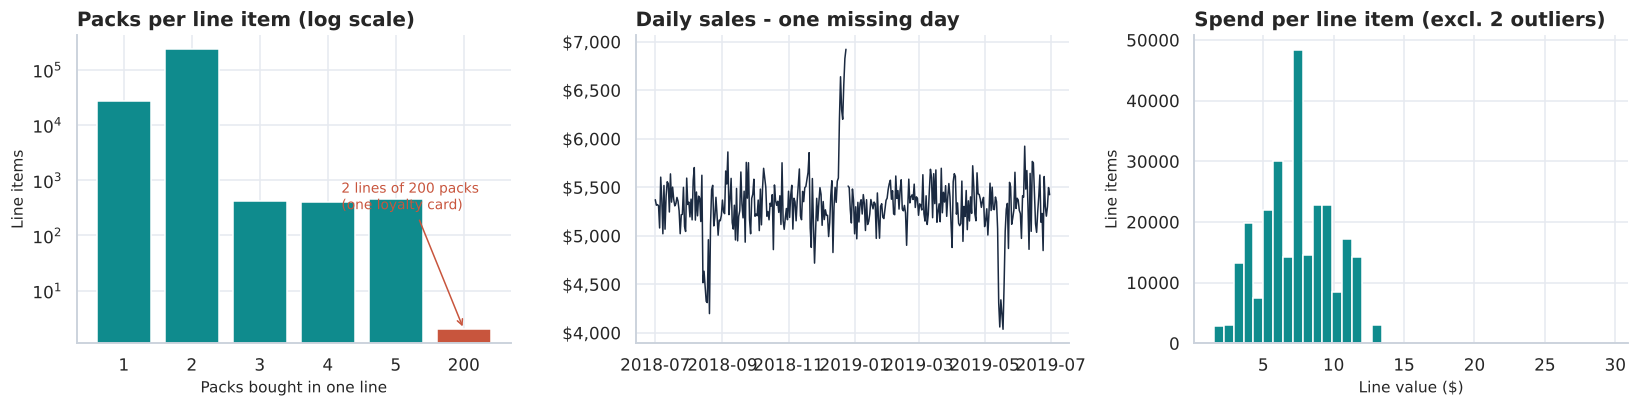

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
q = tx.PROD_QTY.value_counts().sort_index()
ax[0].bar(q.index.astype(str), q.values, color=[RED if i == 200 else TEAL for i in q.index])
ax[0].set_yscale("log"); ax[0].set_title("Packs per line item (log scale)")
ax[0].set_xlabel("Packs bought in one line"); ax[0].set_ylabel("Line items")
ax[0].annotate("2 lines of 200 packs\n(one loyalty card)", xy=(5, 2), xytext=(3.2, 300), color=RED, fontsize=9,
               arrowprops=dict(arrowstyle="->", color=RED))
daily = tx.groupby("DATE").TOT_SALES.sum().reindex(all_days)
ax[1].plot(daily.index, daily.values, color=NAVY, lw=1)
ax[1].set_title("Daily sales - one missing day"); ax[1].yaxis.set_major_formatter(dollar)
ax[1].annotate("25 Dec: no sales\nrecorded", xy=(pd.Timestamp("2018-12-25"), 0), xytext=(pd.Timestamp("2018-10-01"), 2000),
               color=RED, fontsize=9, arrowprops=dict(arrowstyle="->", color=RED))
ax[2].hist(tx.TOT_SALES[tx.TOT_SALES < 40], bins=40, color=TEAL)
ax[2].set_title("Spend per line item (excl. 2 outliers)"); ax[2].set_xlabel("Line value ($)"); ax[2].set_ylabel("Line items")
plt.tight_layout(); save(fig, "01_data_quality"); plt.show()

**What we found**
- **Clean on the basics:** no missing values, no orphan customers, every transaction matches a profile, 1:1 product number/name mapping.
- **1 exact duplicate row** (a double-load).
- **25 Dec 2018 has zero sales** in every store, consistent with a trading-day closure rather than a data gap. I leave it as a true zero.
- **Two 200-pack lines** by one loyalty card (226000); the next-largest line is 5 packs. This is a bulk/commercial buyer, not a typical shopper.
- **Product list contains non-chips:** salsa dips. Product names have messy spacing and brand abbreviations ("Dorito", "Smith", "RRD", "WW", "Snbts", "GrnWves"...).
- `TXN_ID` is not perfectly unique per basket: 2 IDs are shared by two different cards and 4 by two dates. This affects a handful of transactions (<0.01%) and is left as is, but it is the reason I describe transaction counts as "unique TXN_IDs".

**So what:** the data is in good shape, but three issues would have distorted per-customer metrics and category totals if left in.

## 1.3 Cleaning - every decision documented
Each step logs what was removed and why. Note the refinement in step 3: a naive `"salsa"` keyword filter would also delete two genuine chip flavours (Red Rock Deli *Salsa & Mozzarella* and Smiths *Tomato Salsa* chips, 150g). Only the 300g dips are removed.

In [5]:
clean_log = []
def log_step(step, df_before, df_after, reason):
    clean_log.append({"Step": step, "Rows removed": len(df_before) - len(df_after),
                      "Sales removed ($)": round(df_before.TOT_SALES.sum() - df_after.TOT_SALES.sum(), 2),
                      "Rows remaining": len(df_after), "Reason / decision": reason})

df = tx.copy()

# 1. Whitespace in product names is inconsistent (e.g. "Smiths Crinkle Cut  Chips Chicken 170g")
df["PROD_NAME"] = df.PROD_NAME.str.replace(r"\s+", " ", regex=True).str.strip()

# 2. Exact duplicate rows
nxt = df.drop_duplicates(); log_step("Remove exact duplicate rows", df, nxt, "Identical in every field (same card, product, time-stamp, TXN_ID) - a double-load, not a real second purchase"); df = nxt

# 3. Non-chip products: salsa DIPS (300g jars). Salsa-flavoured CHIPS (150g) are kept.
df["PACK_G"] = df.PROD_NAME.str.extract(r"(\d+)\s*[gG]\b", expand=False).astype(float)
is_dip = df.PROD_NAME.str.contains("salsa", case=False) & (df.PACK_G == 300)
print("Removed dip SKUs :", sorted(df.loc[is_dip, "PROD_NAME"].unique()))
print("Kept salsa-flavoured chips:", sorted(df.loc[df.PROD_NAME.str.contains("salsa", case=False) & ~is_dip, "PROD_NAME"].unique()))
nxt = df[~is_dip]; log_step("Remove salsa dips (non-chip category)", df, nxt, "Client category is chips & savoury snacks; dips are a different category with different price/behaviour"); df = nxt

# 4. Outlier customer
whale = df[df.PROD_QTY >= 200].LYLTY_CARD_NBR.unique()
print("Outlier loyalty card(s):", whale, "| their total transactions in dataset:", (df.LYLTY_CARD_NBR.isin(whale)).sum())
nxt = df[~df.LYLTY_CARD_NBR.isin(whale)]; log_step("Remove outlier loyalty card 226000", df, nxt, "Only 2 purchases ever, each 200 packs ($650) - 40x the next-largest line (5 packs); looks like a commercial/bulk buyer, not a retail shopper. Would distort per-customer metrics"); df = nxt

pd.DataFrame(clean_log)

Removed dip SKUs : ['Doritos Salsa Medium 300g', 'Doritos Salsa Mild 300g', 'Old El Paso Salsa Dip Chnky Tom Ht300g', 'Old El Paso Salsa Dip Tomato Med 300g', 'Old El Paso Salsa Dip Tomato Mild 300g', 'Woolworths Medium Salsa 300g', 'Woolworths Mild Salsa 300g']
Kept salsa-flavoured chips: ['Red Rock Deli SR Salsa & Mzzrlla 150g', 'Smiths Crinkle Cut Tomato Salsa 150g']
Outlier loyalty card(s): [226000] | their total transactions in dataset: 2


,Step,Rows removed,Sales removed ($),Rows remaining,Reason / decision
0,Remove exact duplicate rows,1,6.00,264835,"Identical in every field (same card, product, ..."
1,Remove salsa dips (non-chip category),15166,"113,330.60",249669,Client category is chips & savoury snacks; dip...
2,Remove outlier loyalty card 226000,2,"1,300.00",249667,"Only 2 purchases ever, each 200 packs ($650) -..."


**Impact:** 15,169 of 264,836 lines (5.7%) removed in total; virtually all (99.98%) of the removed lines are dips, a separate category. The outlier removal is small in line count but would have inflated that customer's spend to 40x normal.

## 1.4 Feature engineering
Pack size (grams) is parsed from the product name; brand is the first word of the name, standardised (e.g. `DORITO`->Doritos, `RRD`/`Red`->Red Rock Deli, `WW`->Woolworths, `GrnWves`/`Grain`->Grain Waves) so 28 raw labels collapse to 20 real brands.

In [6]:
BRAND_FIX = {"DORITO": "DORITOS", "SMITH": "SMITHS", "SNBTS": "SUNBITES", "INFZNS": "INFUZIONS", "RRD": "RED ROCK DELI",
             "RED": "RED ROCK DELI", "WW": "WOOLWORTHS", "GRNWVES": "GRAIN WAVES", "GRAIN": "GRAIN WAVES",
             "NCC": "NATURAL CHIP CO", "NATURAL": "NATURAL CHIP CO", "BURGER": "BURGER RINGS", "FRENCH": "FRENCH FRIES"}
df["BRAND"] = df.PROD_NAME.str.split().str[0].str.upper().replace(BRAND_FIX).str.title().replace({"Ccs": "CCs"})
df["UNIT_PRICE"] = df.TOT_SALES / df.PROD_QTY
df["MONTH"] = df.DATE.dt.to_period("M").astype(str)

print("Brands after standardising:", df.BRAND.nunique()); print(sorted(df.BRAND.unique()))
print("Pack sizes (g):", sorted(df.PACK_G.astype(int).unique()), "| missing:", df.PACK_G.isna().sum())

Brands after standardising: 20
['Burger Rings', 'CCs', 'Cheetos', 'Cheezels', 'Cobs', 'Doritos', 'French Fries', 'Grain Waves', 'Infuzions', 'Kettle', 'Natural Chip Co', 'Pringles', 'Red Rock Deli', 'Smiths', 'Sunbites', 'Thins', 'Tostitos', 'Twisties', 'Tyrrells', 'Woolworths']
Pack sizes (g): [np.int64(70), np.int64(90), np.int64(110), np.int64(125), np.int64(134), np.int64(135), np.int64(150), np.int64(160), np.int64(165), np.int64(170), np.int64(175), np.int64(180), np.int64(190), np.int64(200), np.int64(210), np.int64(220), np.int64(250), np.int64(270), np.int64(330), np.int64(380)] | missing: 0


## 1.5 Merge transactions with customer profiles
A many-to-one merge on loyalty card number. `validate="m:1"` guards against accidental row multiplication, and the assertion confirms every transaction has a segment.

In [7]:
data = df.merge(cust, on="LYLTY_CARD_NBR", how="left", validate="m:1")
assert data.LIFESTAGE.notna().all(), "Unmatched customers!"
print(f"Merged dataset: {len(data):,} rows | matched to a customer profile: 100%")
print(f"Customers in profile file: {len(cust):,} | customers with >=1 chip purchase after cleaning: {data.LYLTY_CARD_NBR.nunique():,}")
data.to_csv(PROC / "QVI_clean_merged.csv", index=False)
data.head(3)

Merged dataset: 249,667 rows | matched to a customer profile: 100%
Customers in profile file: 72,637 | customers with >=1 chip purchase after cleaning: 71,517


,DATE,STORE_NBR,LYLTY_CARD_NBR,TXN_ID,PROD_NBR,PROD_NAME,PROD_QTY,TOT_SALES,PACK_G,BRAND,UNIT_PRICE,MONTH,LIFESTAGE,PREMIUM_CUSTOMER
0,2018-10-17,1,1000,1,5,Natural Chip Compny SeaSalt175g,2,6.00,175.00,Natural Chip Co,3.00,2018-10,YOUNG SINGLES/COUPLES,Premium
1,2019-05-14,1,1307,348,66,CCs Nacho Cheese 175g,3,6.30,175.00,CCs,2.10,2019-05,MIDAGE SINGLES/COUPLES,Budget
2,2019-05-20,1,1343,383,61,Smiths Crinkle Cut Chips Chicken 170g,2,2.90,170.00,Smiths,1.45,2019-05,MIDAGE SINGLES/COUPLES,Budget


## 1.6 Overall sales performance and KPIs

In [8]:
kpi = {
    "Total sales ($)": data.TOT_SALES.sum(),
    "Units (packs) sold": data.PROD_QTY.sum(),
    "Transactions (unique TXN_ID)": data.TXN_ID.nunique(),
    "Line items": len(data),
    "Unique customers": data.LYLTY_CARD_NBR.nunique(),
    "Active stores": data.STORE_NBR.nunique(),
    "Average transaction value ($)": data.TOT_SALES.sum() / data.TXN_ID.nunique(),
    "Units per transaction": data.PROD_QTY.sum() / data.TXN_ID.nunique(),
    "Sales per customer ($)": data.TOT_SALES.sum() / data.LYLTY_CARD_NBR.nunique(),
    "Transactions per customer": data.TXN_ID.nunique() / data.LYLTY_CARD_NBR.nunique(),
    "Average price per pack ($)": data.TOT_SALES.sum() / data.PROD_QTY.sum(),
}
kpi_df = pd.Series(kpi, name="Value").to_frame()
RESULTS["kpi"] = {k: float(v) for k, v in kpi.items()}
kpi_df

,Value
Total sales ($),"1,819,778.40"
Units (packs) sold,"475,909.00"
Transactions (unique TXN_ID),"248,156.00"
Line items,"249,667.00"
Unique customers,"71,517.00"
Active stores,271.00
Average transaction value ($),7.33
Units per transaction,1.92
Sales per customer ($),25.45
Transactions per customer,3.47


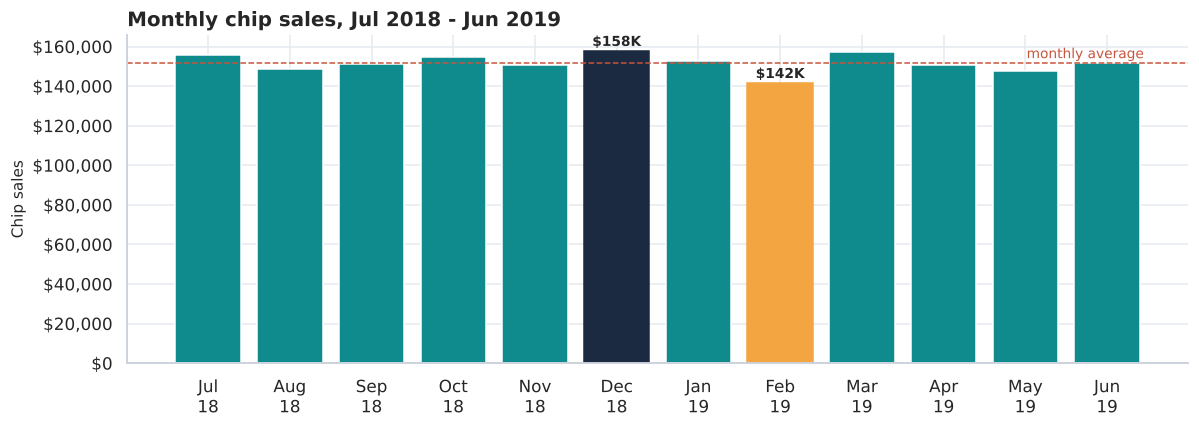

  MONTH      sales  txns  customers
2018-07 155,766.70 21152      17883
2018-08 148,464.85 20959      17791
2018-09 151,153.70 20381      17357
2018-10 154,581.50 20881      17685
2018-11 150,878.30 20479      17417
2018-12 157,820.10 21354      18106
2019-01 152,832.40 20716      17566
2019-02 141,600.30 19100      16400
2019-03 157,116.00 21267      18065
2019-04 150,601.00 20403      17277
2019-05 147,514.85 20950      17709
2019-06 151,448.70 20516      17461


In [9]:
monthly = data.groupby("MONTH").agg(sales=("TOT_SALES", "sum"), txns=("TXN_ID", "nunique"), customers=("LYLTY_CARD_NBR", "nunique")).reset_index()
monthly["label"] = pd.to_datetime(monthly.MONTH).dt.strftime("%b\n%y")
RESULTS["monthly"] = monthly[["MONTH", "sales", "txns", "customers"]].to_dict("records")

fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(monthly.label, monthly.sales, color=TEAL)
hi, lo = monthly.sales.idxmax(), monthly.sales.idxmin()
bars[hi].set_color(NAVY); bars[lo].set_color(AMBER)
for i in (hi, lo):
    ax.text(i, monthly.sales[i] + 2500, f"${monthly.sales[i]/1000:,.0f}K", ha="center", fontweight="bold", fontsize=9)
ax.axhline(monthly.sales.mean(), color=RED, ls="--", lw=1); ax.text(11.45, monthly.sales.mean() + 2500, "monthly average", color=RED, ha="right", fontsize=9)
ax.yaxis.set_major_formatter(dollar); ax.set_ylabel("Chip sales"); ax.set_title("Monthly chip sales, Jul 2018 - Jun 2019")
plt.tight_layout(); save(fig, "02_monthly_sales"); plt.show()
print(monthly[["MONTH", "sales", "txns", "customers"]].to_string(index=False))

**What we found:** $1.82M of chip sales from 248K transactions and 71.5K customers across 271 stores. The average shopper spends **$25.45 a year over 3.5 trips (about $7.33 a trip, 1.9 packs a trip)**. Monthly sales are flat in a $142K-$158K band: February's dip is simply a 28-day month (about $5.06K a day versus $4.93K in January and $5.07K in March), and there is no pronounced seasonal peak.

**So what:** with no seasonality to ride and a stable base, growth must come from *how often* customers buy, *how much* they buy, and *what* they buy (price/mix), which is exactly what the segment analysis below examines.

## 1.7 Customer segmentation: who drives sales?
Segments = lifestage x premium tier (7 x 3 = 21). I use a simple decomposition: **sales = customers x packs per customer x price per pack**. It shows *why* a segment is big (many people? heavy buyers? high prices?).

In [10]:
def seg_metrics(by):
    g = data.groupby(by).agg(sales=("TOT_SALES", "sum"), units=("PROD_QTY", "sum"), txns=("TXN_ID", "nunique"),
                             customers=("LYLTY_CARD_NBR", "nunique"), pack_g=("PACK_G", "mean")).reset_index()
    g["sales_share"] = g.sales / g.sales.sum()
    g["customer_share"] = g.customers / g.customers.sum()
    g["sales_per_customer"] = g.sales / g.customers
    g["txns_per_customer"] = g.txns / g.customers
    g["units_per_customer"] = g.units / g.customers
    g["avg_txn_value"] = g.sales / g.txns
    g["price_per_pack"] = g.sales / g.units
    return g

seg = seg_metrics(["LIFESTAGE", "PREMIUM_CUSTOMER"]).sort_values("sales", ascending=False)
by_life = seg_metrics("LIFESTAGE").sort_values("sales", ascending=False)
by_prem = seg_metrics("PREMIUM_CUSTOMER").sort_values("sales", ascending=False)
RESULTS["segments"] = seg.to_dict("records"); RESULTS["by_lifestage"] = by_life.to_dict("records"); RESULTS["by_premium"] = by_prem.to_dict("records")
print("TOP 8 SEGMENTS (of 21)"); display(seg.head(8).round(2))
print("BY LIFESTAGE"); display(by_life.round(3))
print("BY PREMIUM TIER"); display(by_prem.round(3))

TOP 8 SEGMENTS (of 21)


,LIFESTAGE,PREMIUM_CUSTOMER,sales,units,txns,customers,pack_g,sales_share,customer_share,sales_per_customer,txns_per_customer,units_per_customer,avg_txn_value,price_per_pack
6,OLDER FAMILIES,Budget,"158,379.95",42425,21612,4622,175.20,0.09,0.06,34.27,4.68,9.18,7.33,3.73
19,YOUNG SINGLES/COUPLES,Mainstream,"148,337.20",36509,19642,7930,178.11,0.08,0.11,18.71,2.48,4.60,7.55,4.06
13,RETIREES,Mainstream,"146,328.75",38114,20107,6382,174.92,0.08,0.09,22.93,3.15,5.97,7.28,3.84
15,YOUNG FAMILIES,Budget,"130,919.05",34936,17860,3961,175.13,0.07,0.06,33.05,4.51,8.82,7.33,3.75
9,OLDER SINGLES/COUPLES,Budget,"128,683.80",33204,17251,4864,175.08,0.07,0.07,26.46,3.55,6.83,7.46,3.88
10,OLDER SINGLES/COUPLES,Mainstream,"125,737.10",33018,17171,4870,174.50,0.07,0.07,25.82,3.53,6.78,7.32,3.81
11,OLDER SINGLES/COUPLES,Premium,"124,457.05",32042,16653,4694,176.20,0.07,0.07,26.51,3.55,6.83,7.47,3.88
12,RETIREES,Budget,"106,606.20",27192,14284,4396,176.14,0.06,0.06,24.25,3.25,6.19,7.46,3.92


BY LIFESTAGE


,LIFESTAGE,sales,units,txns,customers,pack_g,sales_share,customer_share,sales_per_customer,txns_per_customer,units_per_customer,avg_txn_value,price_per_pack
3,OLDER SINGLES/COUPLES,"378,877.95",98264,51073,14428,175.25,0.21,0.20,26.26,3.54,6.81,7.42,3.86
4,RETIREES,"344,886.90",88819,46703,14599,175.60,0.19,0.20,23.62,3.20,6.08,7.38,3.88
2,OLDER FAMILIES,"331,643.80",89075,45353,9658,174.87,0.18,0.14,34.34,4.70,9.22,7.31,3.72
5,YOUNG FAMILIES,"297,396.00",79622,40728,9058,174.55,0.16,0.13,32.83,4.50,8.79,7.30,3.73
6,YOUNG SINGLES/COUPLES,"245,307.50",62885,34202,14104,176.08,0.14,0.20,17.39,2.42,4.46,7.17,3.90
0,MIDAGE SINGLES/COUPLES,"174,010.50",45058,23556,7167,175.74,0.10,0.10,24.28,3.29,6.29,7.39,3.86
1,NEW FAMILIES,"47,655.75",12186,6541,2503,174.92,0.03,0.04,19.04,2.61,4.87,7.29,3.91


BY PREMIUM TIER


,PREMIUM_CUSTOMER,sales,units,txns,customers,pack_g,sales_share,customer_share,sales_per_customer,txns_per_customer,units_per_customer,avg_txn_value,price_per_pack
1,Mainstream,"706,252.50",182813,95592,28807,175.68,0.39,0.40,24.52,3.32,6.35,7.39,3.86
0,Budget,"636,632.85",167747,87238,24094,175.01,0.35,0.34,26.42,3.62,6.96,7.30,3.79
2,Premium,"476,893.05",125349,65328,18616,175.06,0.26,0.26,25.62,3.51,6.73,7.30,3.81


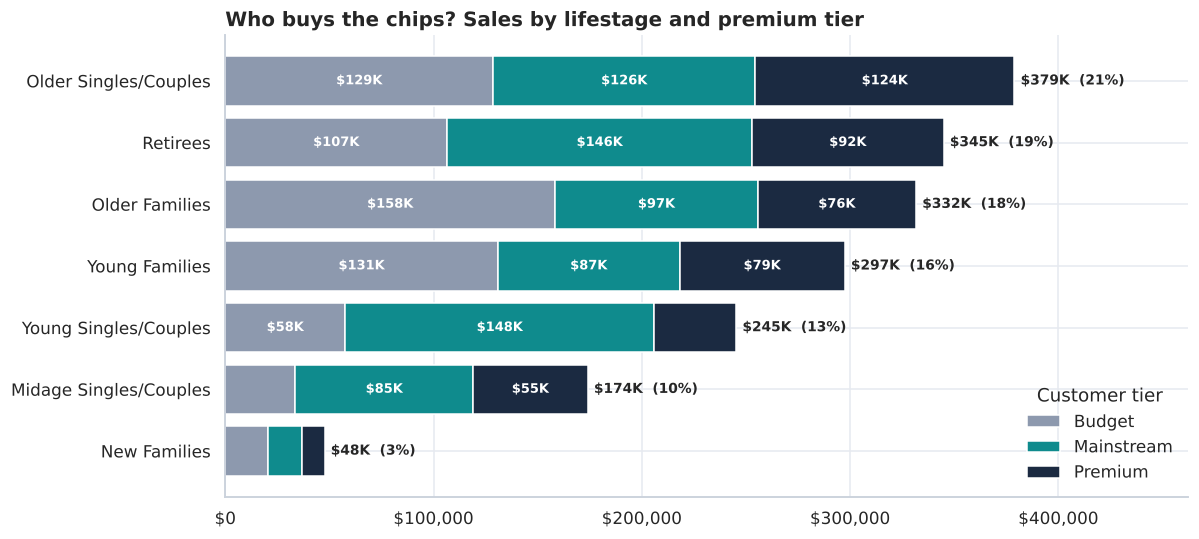

In [11]:
order = by_life.LIFESTAGE.tolist()[::-1]
pv = seg.pivot(index="LIFESTAGE", columns="PREMIUM_CUSTOMER", values="sales").loc[order][["Budget", "Mainstream", "Premium"]]
fig, ax = plt.subplots(figsize=(11, 5))
left = np.zeros(len(pv))
for tier in pv.columns:
    ax.barh(pv.index.str.title(), pv[tier], left=left, color=PREMIUM_PAL[tier], label=tier, edgecolor="white")
    for i, v in enumerate(pv[tier]):
        if v > 40000: ax.text(left[i] + v / 2, i, f"${v/1000:,.0f}K", ha="center", va="center", color="white", fontsize=8.5, fontweight="bold")
    left += pv[tier].values
for i, tot in enumerate(left): ax.text(tot + 3000, i, f"${tot/1000:,.0f}K  ({tot/seg.sales.sum():.0%})", va="center", fontsize=9, fontweight="bold")
ax.xaxis.set_major_formatter(dollar); ax.set_xlim(0, left.max() * 1.22)
ax.set_title("Who buys the chips? Sales by lifestage and premium tier"); ax.legend(title="Customer tier", loc="lower right", frameon=False)
plt.tight_layout(); save(fig, "03_sales_by_segment"); plt.show()

**What we found:** Older Singles/Couples (21%), Retirees (19%) and Older Families (18%) are the three largest lifestages. At segment level the top three are **Older Families-Budget ($158K, 8.7%)**, **Young Singles/Couples-Mainstream ($148K, 8.2%)** and **Retirees-Mainstream ($146K, 8.0%)**; together they are 25% of sales. By tier, Mainstream is 39% of sales, Budget 35% and Premium 26%, almost exactly mirroring each tier's share of customers (40% / 34% / 26%).

**So what:** premium tier tells you *how many* customers there are, not *how much they spend*. Lifestage is the better lever, as the next chart shows.

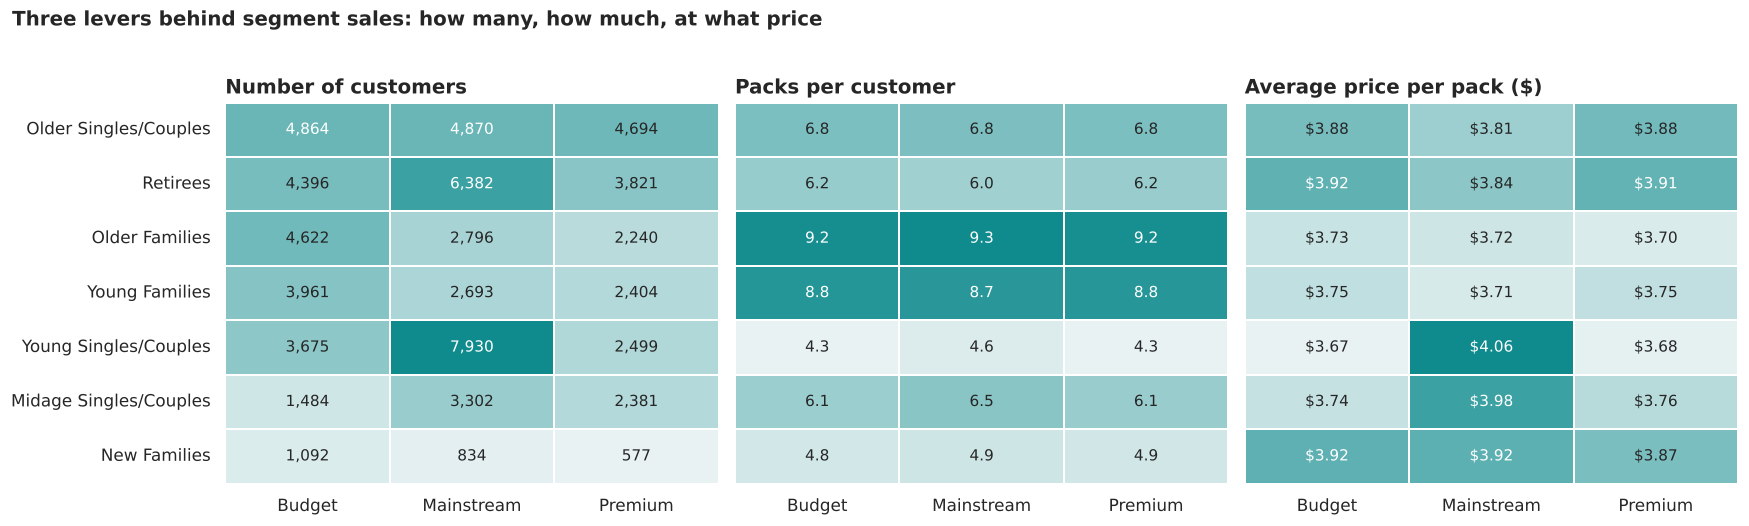

In [12]:
# Sales = (number of customers) x (packs per customer) x (price per pack). Which lever explains each segment's size?
tiers = ["Budget", "Mainstream", "Premium"]
mats = [("customers", "Number of customers", "{:,.0f}"), ("units_per_customer", "Packs per customer", "{:.1f}"), ("price_per_pack", "Average price per pack ($)", "${:.2f}")]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (col, ttl, fmt) in zip(axes, mats):
    m = seg.pivot(index="LIFESTAGE", columns="PREMIUM_CUSTOMER", values=col).loc[order[::-1]][tiers]
    m.index = m.index.str.title()
    sns.heatmap(m, annot=m.map(lambda v: fmt.format(v)), fmt="", cmap=sns.light_palette(TEAL, as_cmap=True), cbar=False, ax=ax, linewidths=1, linecolor="white")
    ax.set_title(ttl); ax.set_xlabel(""); ax.set_ylabel("")
    if col != "customers": ax.set_yticklabels([])
plt.suptitle("Three levers behind segment sales: how many, how much, at what price", x=0.01, ha="left", fontweight="bold", fontsize=13, y=1.03)
plt.tight_layout(); save(fig, "04_segment_drivers"); plt.show()

**What we found:** Look across each row: **packs per customer are identical across tiers within a lifestage** (Older Families: 9.2 / 9.3 / 9.2). Lifestage sets volume; tier does not. Two segments stand out on the other levers: **Mainstream Young Singles/Couples is the largest customer group (7,930) with a very low 4.6 packs each**, and it pays the highest price per pack ($4.06). Mainstream Mid-age singles/couples show the same price pattern ($3.98).

**So what:** the biggest *customer* pool is lightly engaged. That is where an incremental trip is cheapest to win.

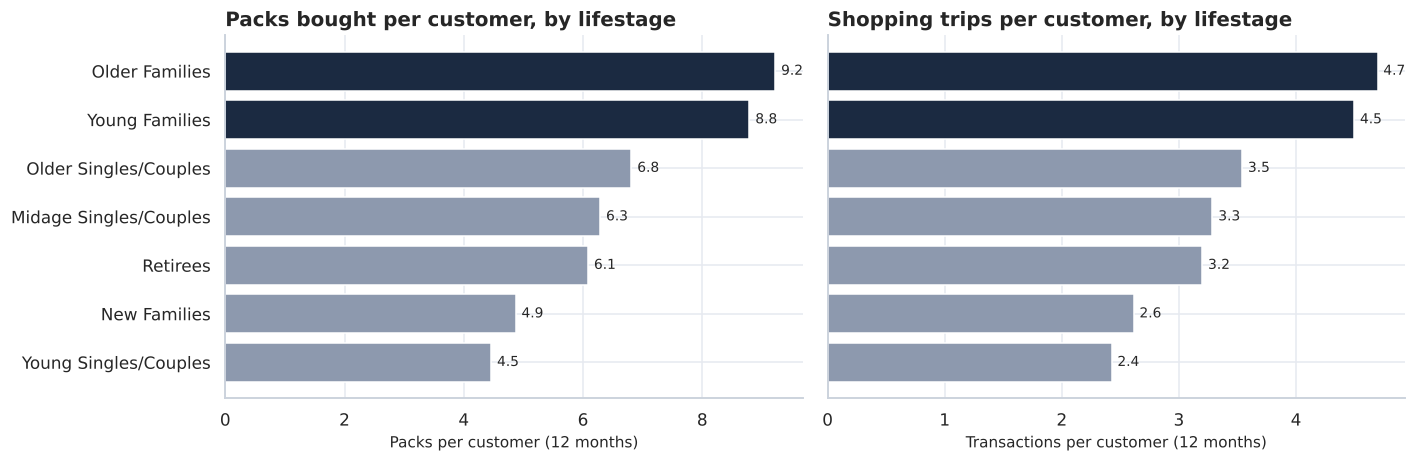

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
bl = by_life.sort_values("units_per_customer")
ax[0].barh(bl.LIFESTAGE.str.title(), bl.units_per_customer, color=[NAVY if "FAMILIES" in s and s != "NEW FAMILIES" else GREY for s in bl.LIFESTAGE])
for i, v in enumerate(bl.units_per_customer): ax[0].text(v + .1, i, f"{v:.1f}", va="center", fontsize=9)
ax[0].set_title("Packs bought per customer, by lifestage"); ax[0].set_xlabel("Packs per customer (12 months)")
bl = by_life.sort_values("txns_per_customer")
ax[1].barh(bl.LIFESTAGE.str.title(), bl.txns_per_customer, color=[NAVY if "FAMILIES" in s and s != "NEW FAMILIES" else GREY for s in bl.LIFESTAGE])
for i, v in enumerate(bl.txns_per_customer): ax[1].text(v + .05, i, f"{v:.1f}", va="center", fontsize=9)
ax[1].set_title("Shopping trips per customer, by lifestage"); ax[1].set_xlabel("Transactions per customer (12 months)"); ax[1].set_yticklabels([])
plt.tight_layout(); save(fig, "05_purchase_frequency"); plt.show()

**What we found:** Older and Young Families buy 4.5-4.7 times a year and 8.8-9.2 packs, about double Young Singles/Couples (2.4 trips, 4.5 packs). Families are 26% of customers but 35% of sales, and a family customer is worth $33-34 a year against $17 for a young single/couple.

**So what:** families are the revenue engine and should be protected (availability of large and value packs). Young singles/couples are the reach-without-frequency opportunity.

### Do Mainstream young and mid-age singles/couples really pay more per pack?
Tested with a one-sided Welch t-test at line-item level (unequal variances allowed).

In [14]:
# Do Mainstream young/mid-age singles & couples pay more per pack? Test at line-item level (Welch t-test, one-sided)
grp = data[data.LIFESTAGE.isin(["YOUNG SINGLES/COUPLES", "MIDAGE SINGLES/COUPLES"])]
main = grp[grp.PREMIUM_CUSTOMER == "Mainstream"].UNIT_PRICE
other = grp[grp.PREMIUM_CUSTOMER != "Mainstream"].UNIT_PRICE
t_stat, p_val = stats.ttest_ind(main, other, equal_var=False, alternative="greater")
ci = stats.ttest_ind(main, other, equal_var=False).confidence_interval()
print(f"Mainstream young/mid-age singles & couples : ${main.mean():.3f} per pack (n={len(main):,})")
print(f"Budget + Premium young/mid-age s&c         : ${other.mean():.3f} per pack (n={len(other):,})")
print(f"Difference ${main.mean()-other.mean():.3f} | 95% CI ({ci.low:.3f}, {ci.high:.3f}) | Welch t = {t_stat:.1f} | one-sided p = {p_val:.2e}")
RESULTS["price_test"] = {"main_mean": float(main.mean()), "other_mean": float(other.mean()), "diff": float(main.mean() - other.mean()),
                         "ci_low": float(ci.low), "ci_high": float(ci.high), "t": float(t_stat), "p": float(p_val), "n_main": int(len(main)), "n_other": int(len(other))}

Mainstream young/mid-age singles & couples : $4.028 per pack (n=30,905)
Budget + Premium young/mid-age s&c         : $3.692 per pack (n=27,104)
Difference $0.336 | 95% CI (0.319, 0.353) | Welch t = 38.1 | one-sided p = 0.00e+00


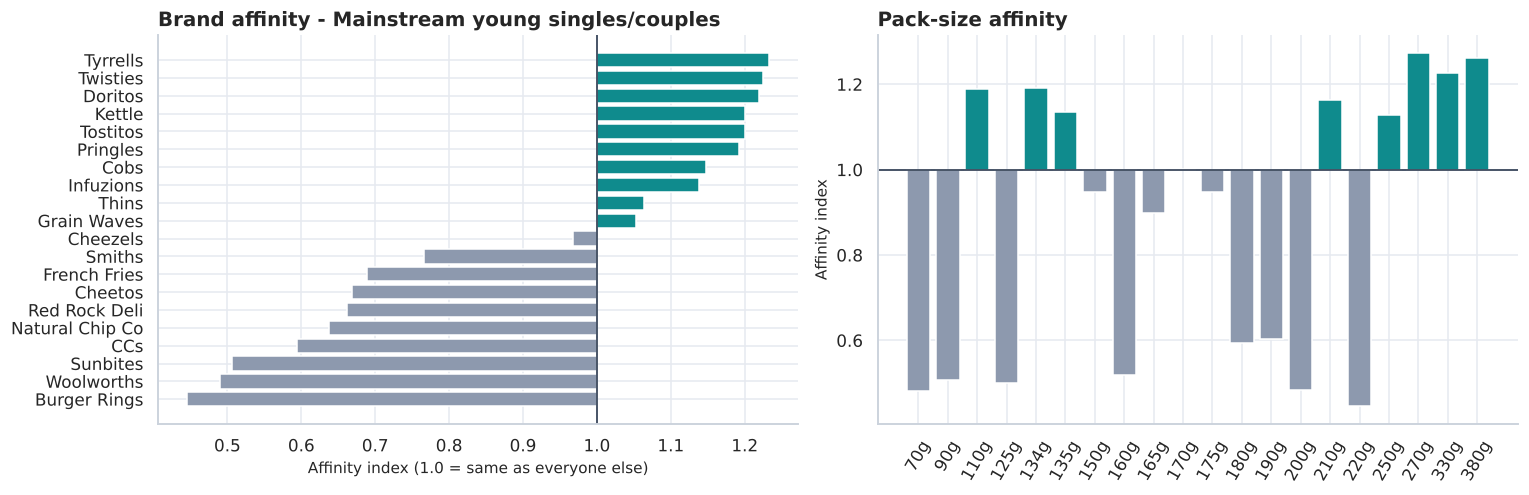

          affinity  target_share  other_share
BRAND                                        
Tyrrells      1.23          0.03         0.03
Twisties      1.22          0.05         0.04
Doritos       1.22          0.12         0.10
Kettle        1.20          0.20         0.16
              affinity  target_share  other_share
BRAND                                            
Sunbites          0.51          0.01         0.01
Woolworths        0.49          0.02         0.05
Burger Rings      0.45          0.00         0.01
        affinity  target_share  other_share
PACK_G                                     
270.00      1.27          0.03         0.03
380.00      1.26          0.03         0.03
330.00      1.23          0.06         0.05
134.00      1.19          0.12         0.10


In [15]:
# Affinity index = share of the target segment's sales on a brand / share of everyone else's sales on that brand. >1 = over-indexes.
TARGET = (data.LIFESTAGE == "YOUNG SINGLES/COUPLES") & (data.PREMIUM_CUSTOMER == "Mainstream")
def affinity(col):
    a = data[TARGET].groupby(col).PROD_QTY.sum(); a = a / a.sum()
    b = data[~TARGET].groupby(col).PROD_QTY.sum(); b = b / b.sum()
    return (a / b).sort_values(ascending=False).rename("affinity").to_frame().join(a.rename("target_share")).join(b.rename("other_share"))
brand_aff = affinity("BRAND"); pack_aff = affinity("PACK_G")
brand_aff = brand_aff[data.groupby("BRAND").PROD_QTY.sum().reindex(brand_aff.index) > 2000]   # ignore tiny brands
RESULTS["brand_affinity"] = brand_aff.reset_index().to_dict("records"); RESULTS["pack_affinity"] = pack_aff.reset_index().to_dict("records")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
ba = brand_aff.sort_values("affinity"); ax[0].barh(ba.index, ba.affinity - 1, left=1, color=[TEAL if v > 1 else GREY for v in ba.affinity])
ax[0].axvline(1, color=NAVY, lw=1); ax[0].set_title("Brand affinity - Mainstream young singles/couples"); ax[0].set_xlabel("Affinity index (1.0 = same as everyone else)")
pa = pack_aff.sort_index(); ax[1].bar(pa.index.astype(int).astype(str) + "g", pa.affinity - 1, bottom=1, color=[TEAL if v > 1 else GREY for v in pa.affinity])
ax[1].axhline(1, color=NAVY, lw=1); ax[1].set_title("Pack-size affinity"); ax[1].set_ylabel("Affinity index"); ax[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); save(fig, "06_affinity"); plt.show()
print(brand_aff.round(3).head(4)); print(brand_aff.round(3).tail(3)); print(pack_aff.round(3).sort_values("affinity", ascending=False).head(4))

**What we found:** Mainstream young singles/couples pay **$4.03 vs $3.69 per pack** than Budget/Premium peers in the same lifestages; the $0.34 difference (95% CI $0.32-$0.35) is highly significant (n = 58K lines). Their brand mix explains it: they over-index (by units) on **Tyrrells (1.23x), Twisties (1.22x), Doritos (1.22x) and Kettle (1.20x)** and under-index on Burger Rings (0.45x), Woolworths (0.49x) and Sunbites (0.51x). They also favour **bigger packs**: 270g (1.27x), 380g (1.26x), 330g (1.23x), plus 134g (Pringles, 1.19x).

**So what:** this group buys branded, premium, shareable formats, which suggests social/occasion buying. That is a clear brief for promotions and ranging. *(Association, not proof of motive; price per pack is driven by brand and size mix, not by a different price for the same item.)*

In [16]:
# Sizing arithmetic (NOT a forecast): what is one extra pack per customer worth in the biggest customer segment?
row = seg[(seg.LIFESTAGE == "YOUNG SINGLES/COUPLES") & (seg.PREMIUM_CUSTOMER == "Mainstream")].iloc[0]
fam = seg[seg.LIFESTAGE.isin(["OLDER FAMILIES", "YOUNG FAMILIES"])]
opp = {"customers": int(row.customers), "units_per_customer": row.units_per_customer, "price_per_pack": row.price_per_pack,
       "plus1_pack_value": row.customers * 1 * row.price_per_pack, "plus1_pack_pct_of_total": row.customers * row.price_per_pack / data.TOT_SALES.sum(),
       "family_sales_share": fam.sales.sum() / seg.sales.sum(), "family_customer_share": fam.customers.sum() / seg.customers.sum(),
       "family_units_per_customer": fam.units.sum() / fam.customers.sum()}
RESULTS["opportunity"] = {k: float(v) for k, v in opp.items()}
for k, v in opp.items(): print(f"{k:28s} {v:,.3f}")

customers                    7,930.000
units_per_customer           4.604
price_per_pack               4.063
plus1_pack_value             32,219.836
plus1_pack_pct_of_total      0.018
family_sales_share           0.346
family_customer_share        0.262
family_units_per_customer    9.014


**Sizing, as simple arithmetic (not a forecast):** one extra pack a year for each Mainstream Young Singles/Couples customer = 7,930 x $4.06 = **~$32K, or 1.8% of total chip sales**.

## 1.8 Product performance
Top products by revenue and by volume. Dark bars appear in both lists.

1 of the top-10 revenue products are also in the top-10 by volume
Top 10 products = 19.0% of sales | Top 20 = 34.7% | of 107 SKUs


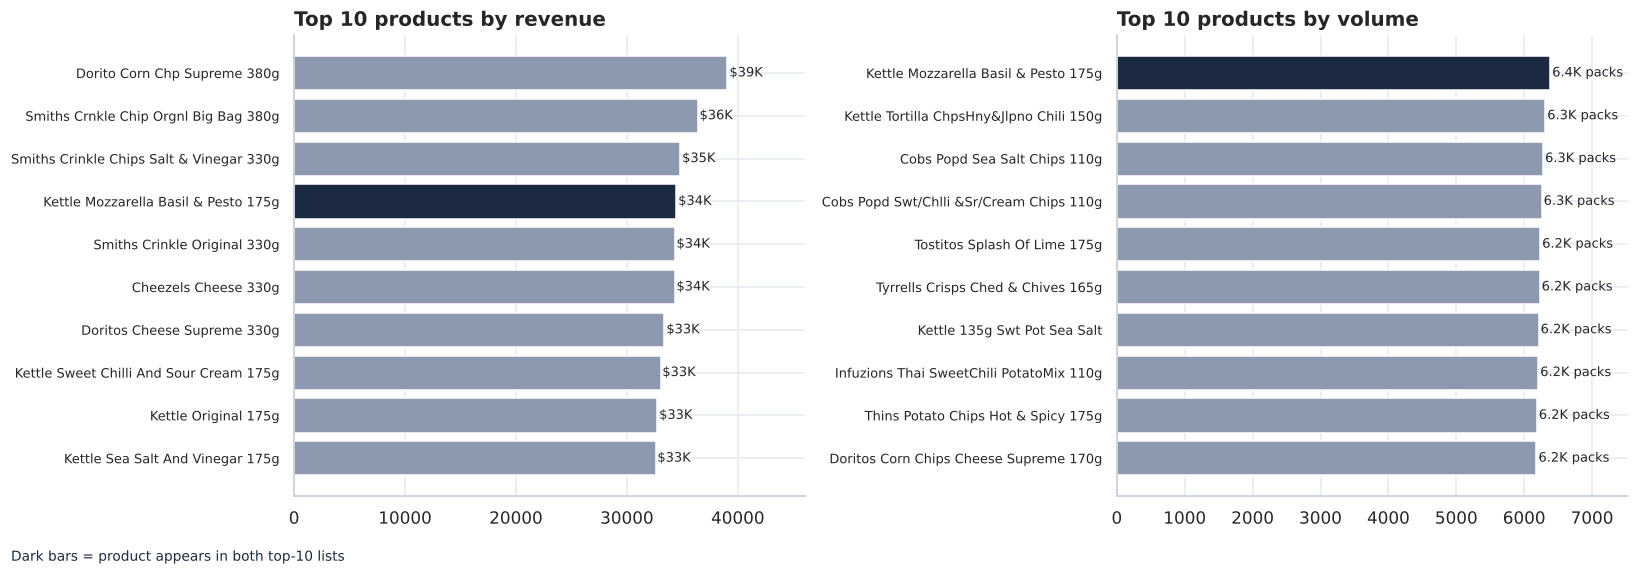

In [17]:
prod = data.groupby("PROD_NAME").agg(sales=("TOT_SALES", "sum"), units=("PROD_QTY", "sum"), txns=("TXN_ID", "nunique"), pack_g=("PACK_G", "first"), brand=("BRAND", "first")).reset_index()
prod["price_per_pack"] = prod.sales / prod.units; prod["price_per_100g"] = prod.price_per_pack / prod.pack_g * 100
prod["sales_share"] = prod.sales / prod.sales.sum()
top_rev, top_qty = prod.nlargest(10, "sales"), prod.nlargest(10, "units")
RESULTS["top_products_revenue"] = top_rev.to_dict("records"); RESULTS["top_products_qty"] = top_qty.to_dict("records")
overlap = set(top_rev.PROD_NAME) & set(top_qty.PROD_NAME)
print(f"{len(overlap)} of the top-10 revenue products are also in the top-10 by volume")
print(f"Top 10 products = {top_rev.sales.sum()/prod.sales.sum():.1%} of sales | Top 20 = {prod.nlargest(20,'sales').sales.sum()/prod.sales.sum():.1%} | of {len(prod)} SKUs")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, d, col, ttl, fmt in [(ax[0], top_rev, "sales", "Top 10 products by revenue", lambda v: f"${v/1000:,.0f}K"), (ax[1], top_qty, "units", "Top 10 products by volume", lambda v: f"{v/1000:,.1f}K packs")]:
    d = d.sort_values(col); a.barh(d.PROD_NAME, d[col], color=[NAVY if n in overlap else GREY for n in d.PROD_NAME])
    for i, v in enumerate(d[col]): a.text(v * 1.005, i, fmt(v), va="center", fontsize=8.5)
    a.set_title(ttl); a.set_xlim(0, d[col].max() * 1.18); a.tick_params(axis="y", labelsize=8.5)
fig.text(0.01, -0.03, "Dark bars = product appears in both top-10 lists", color=NAVY, fontsize=9)
plt.tight_layout(); save(fig, "07_top_products"); plt.show()

**What we found:** only **1 of the top-10 revenue products is also a top-10 volume product** (Kettle Mozzarella Basil & Pesto 175g). The revenue leaders are mostly **330-380g bags and Kettle 175g** priced $5.40-$6.39 a pack. The volume leaders are 110-175g packs at $3.30-$5.40. Volume is remarkably flat: the top-10 sell between 6,180 and 6,381 packs each, so the ranking is driven almost entirely by price and pack size, not by popularity. The top 10 of 107 products make 19% of sales (top 20: 35%); demand is spread widely.

**So what:** no single "hero" SKU to protect; the revenue lever is mix toward larger and premium packs, and availability of those.

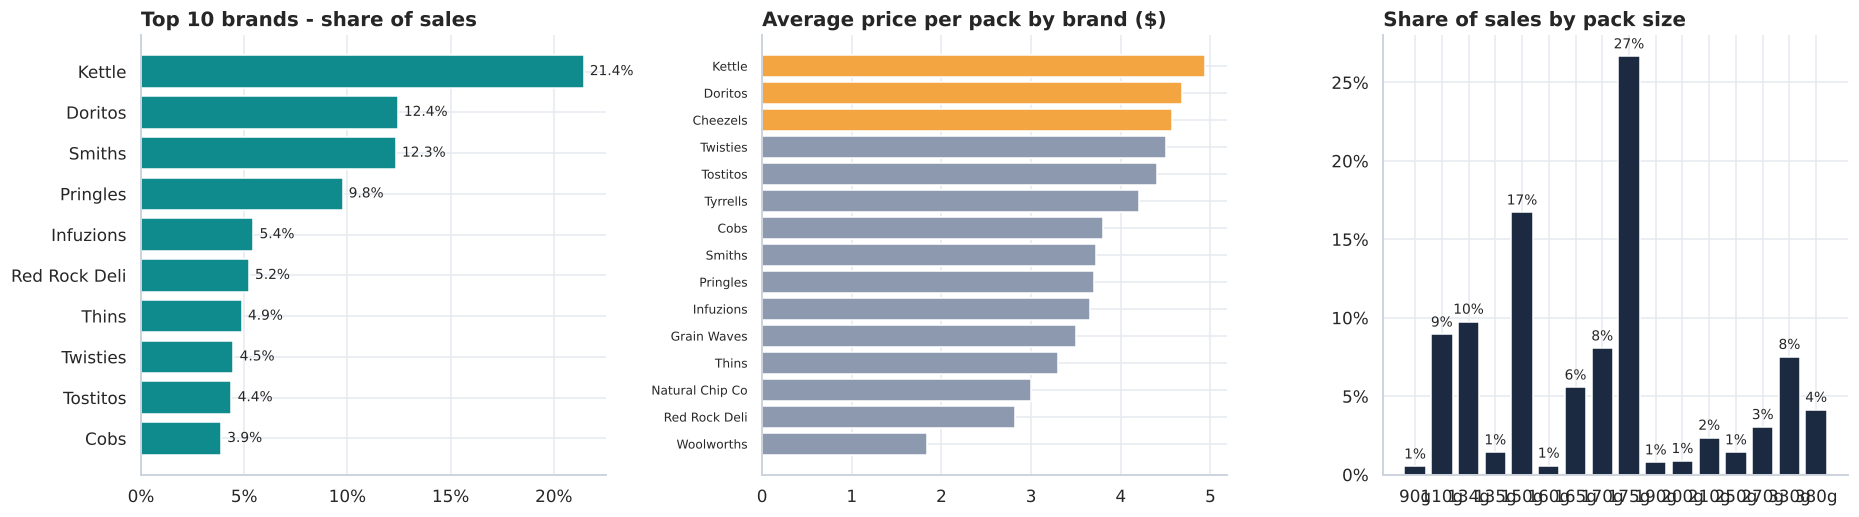

        BRAND      sales  units  skus  share  price_per_pack
       Kettle 390,239.80  79051    13   0.21            4.94
      Doritos 226,329.90  48331     8   0.12            4.68
       Smiths 224,654.20  60337    18   0.12            3.72
     Pringles 177,655.50  48019     8   0.10            3.70
    Infuzions  99,047.60  27119     5   0.05            3.65
Red Rock Deli  95,046.00  33646    12   0.05            2.83
 PACK_G      sales  units  skus  share  price_per_pack  price_per_100g
 175.00 485,431.40 126465    30   0.27            3.84            2.19
 150.00 304,288.50  82174    20   0.17            3.70            2.47
 134.00 177,655.50  48019     8   0.10            3.70            2.76
 110.00 162,765.40  42835     7   0.09            3.80            3.45
 170.00 146,673.00  38088     9   0.08            3.85            2.27


In [18]:
brand = data.groupby("BRAND").agg(sales=("TOT_SALES", "sum"), units=("PROD_QTY", "sum"), skus=("PROD_NBR", "nunique")).reset_index()
brand["share"] = brand.sales / brand.sales.sum(); brand["price_per_pack"] = brand.sales / brand.units
pack = data.groupby("PACK_G").agg(sales=("TOT_SALES", "sum"), units=("PROD_QTY", "sum"), skus=("PROD_NBR", "nunique")).reset_index()
pack["share"] = pack.sales / pack.sales.sum(); pack["price_per_pack"] = pack.sales / pack.units; pack["price_per_100g"] = pack.price_per_pack / pack.PACK_G * 100
RESULTS["brand"] = brand.sort_values("sales", ascending=False).to_dict("records"); RESULTS["pack"] = pack.to_dict("records")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
b = brand.nlargest(10, "sales").sort_values("sales")
ax[0].barh(b.BRAND, b.share, color=TEAL); ax[0].xaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); ax[0].set_title("Top 10 brands - share of sales")
for i, v in enumerate(b.share): ax[0].text(v + .003, i, f"{v:.1%}", va="center", fontsize=9)
b = brand.sort_values("price_per_pack").query("sales > 20000")
ax[1].barh(b.BRAND, b.price_per_pack, color=[AMBER if v > 4.5 else GREY for v in b.price_per_pack]); ax[1].set_title("Average price per pack by brand ($)"); ax[1].tick_params(axis="y", labelsize=8)
p = pack[pack.share > 0.005]
ax[2].bar(p.PACK_G.astype(int).astype(str) + "g", p.share, color=NAVY); ax[2].yaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); ax[2].set_title("Share of sales by pack size")
for i, v in enumerate(p.share): ax[2].text(i, v + .005, f"{v:.0%}", ha="center", fontsize=9)
plt.tight_layout(); save(fig, "08_brand_pack"); plt.show()
print(brand.sort_values("sales", ascending=False).head(6).round(3).to_string(index=False)); print(pack.sort_values("sales", ascending=False).head(5).round(3).to_string(index=False))

**What we found:** **Kettle is the brand: 21% of sales ($390K)** with 13 SKUs at $4.94 a pack, followed by Doritos (12%, $4.68), Smiths (12%, $3.72) and Pringles (10%, $3.70). Red Rock Deli, a top-6 brand, sells at only $2.82 a pack. 175g is the dominant pack size (27% of sales, 30 SKUs), then 150g (17%) and 134g (10%).

**So what:** Kettle commands a clear price premium and is the natural anchor for premium-led promotions; Smiths/Pringles/Red Rock Deli compete on price.

## 1.9 Stage 1 conclusions: what the client should do

| Priority | Recommendation | Evidence |
|---|---|---|
| 1 | **Grow frequency in Mainstream Young Singles/Couples** with premium-brand sharing packs (Kettle, Doritos, Tyrrells; 270-380g) and occasion-led promotions. | Largest customer group (7,930), only 4.6 packs each, $4.06/pack, over-indexes on exactly those brands/sizes. +1 pack = ~$32K (1.8%). |
| 2 | **Protect the family base**: keep large and value packs available and well-priced. | 26% of customers, 35% of sales, ~9 packs each. |
| 3 | **Lead with premium/large formats in range and space decisions.** | Revenue leaders are 330-380g bags and Kettle; volume per SKU is flat. |
| 4 | **Treat Retirees and Older Singles/Couples as a stable core**, not a growth lever. | 40% of sales, mid-range frequency, no standout price premium. |

*Facts: sections 1.2-1.8. Assumptions: revenue not margin; one year of data. Recommendations are judgement and should be tested.*

<a id="2"></a>
# 2. Stage 2: Did the new store layout work?
**Question:** did the new layout in trial stores 77, 86 and 88 lift sales (Feb-Apr 2019)?

**Approach:** a trial store cannot be compared to "everyone else"; stores differ in size and trend. For each trial store I find a *control* store that behaved most similarly **before** the trial, scale the control to the trial store's size, then ask whether the trial-period gap is larger than normal month-to-month noise.

**Observed improvement is not the same as a statistically significant improvement.** A bigger number in a trial store is only evidence if it is bigger than the gap we would see anyway.

In [19]:
# ---- Experiment definition (INPUTS - not contained in the data files; see Assumptions) ----
TRIAL_STORES = [77, 86, 88]
PRE_START, PRE_END = "2018-07", "2019-01"       # 7 pre-trial months
TRIAL_START, TRIAL_END = "2019-02", "2019-04"   # 3 trial months

# Monthly store metrics. Customers/transactions are DISTINCT counts within each store-month.
sm = data.groupby(["STORE_NBR", "MONTH"]).agg(sales=("TOT_SALES", "sum"), customers=("LYLTY_CARD_NBR", "nunique"),
                                                txns=("TXN_ID", "nunique"), units=("PROD_QTY", "sum")).reset_index()
sm["txn_per_cust"] = sm.txns / sm.customers; sm["units_per_txn"] = sm.units / sm.txns; sm["price_per_pack"] = sm.sales / sm.units

# Only stores observed in ALL 12 months can be matched on a full pre-trial history
months_seen = sm.groupby("STORE_NBR").MONTH.nunique()
full_stores = months_seen[months_seen == 12].index
print(f"Stores in data: {sm.STORE_NBR.nunique()} | with all 12 months: {len(full_stores)} | excluded (incomplete history): {sorted(set(sm.STORE_NBR) - set(full_stores))}")
assert all(s in full_stores for s in TRIAL_STORES)
sm = sm[sm.STORE_NBR.isin(full_stores)].copy()
pre = sm[(sm.MONTH >= PRE_START) & (sm.MONTH <= PRE_END)]
print("\nTrial stores - pre-trial monthly averages:")
pre[pre.STORE_NBR.isin(TRIAL_STORES)].groupby("STORE_NBR")[["sales", "customers", "txns"]].mean().round(1)

Stores in data: 271 | with all 12 months: 259 | excluded (incomplete history): [11, 31, 44, 76, 85, 92, 117, 177, 193, 206, 218, 252]

Trial stores - pre-trial monthly averages:


,sales,customers,txns
STORE_NBR,,,
77,232.90,41.10,43.40
86,837.80,96.30,120.00
88,"1,261.80",121.10,145.40


## 2.1 Choosing control stores (not randomly)
Candidates are every store with all 12 months of data, excluding the other trial stores. Each candidate is scored on the 7 pre-trial months for three metrics (**sales, customers, transactions**) using two components:
- **Trend similarity:** Pearson correlation of monthly values.
- **Size similarity:** 1 - normalised mean absolute gap (a control that is the right size).

Score = 50% correlation + 50% size, averaged across the three metrics. The highest score wins.

In [20]:
METRICS = ["sales", "customers", "txns"]
candidates = [s for s in full_stores if s not in TRIAL_STORES]     # other trial stores can't be controls

def score_candidates(trial, cands):
    rows = {}
    for m in METRICS:
        piv = pre.pivot(index="MONTH", columns="STORE_NBR", values=m)
        corr = piv[cands].apply(lambda c: c.corr(piv[trial]))                       # trend similarity
        dist = piv[cands].sub(piv[trial], axis=0).abs().mean()                       # size similarity (mean abs gap)
        mag = 1 - (dist - dist.min()) / (dist.max() - dist.min())                    # 1 = closest in size
        rows[f"corr_{m}"], rows[f"mag_{m}"] = corr, mag
    out = pd.DataFrame(rows)
    out["score"] = 0.5 * out[[f"corr_{m}" for m in METRICS]].mean(axis=1) + 0.5 * out[[f"mag_{m}" for m in METRICS]].mean(axis=1)
    return out.sort_values("score", ascending=False)

scores = {t: score_candidates(t, candidates) for t in TRIAL_STORES}
CONTROL = {t: int(scores[t].index[0]) for t in TRIAL_STORES}
for t in TRIAL_STORES:
    print(f"\nTrial store {t} - top 5 candidate controls"); display(scores[t].head(5).round(3))
print("Selected controls:", CONTROL)
RESULTS["control_map"] = CONTROL
RESULTS["match_scores"] = {str(t): scores[t].head(5).reset_index().rename(columns={"index": "STORE_NBR"}).to_dict("records") for t in TRIAL_STORES}


Trial store 77 - top 5 candidate controls


,corr_sales,mag_sales,corr_customers,mag_customers,corr_txns,mag_txns,score
STORE_NBR,,,,,,,
233,0.98,1.00,0.96,1.00,0.97,1.00,0.99
41,0.82,0.97,0.84,0.99,0.84,1.00,0.91
254,0.69,0.93,0.96,0.94,0.83,0.95,0.88
50,0.92,0.99,0.72,0.95,0.62,0.95,0.86
27,0.64,0.87,0.84,0.98,0.74,0.99,0.84



Trial store 86 - top 5 candidate controls


,corr_sales,mag_sales,corr_customers,mag_customers,corr_txns,mag_txns,score
STORE_NBR,,,,,,,
155,0.85,1.00,0.82,1.00,0.67,0.99,0.89
114,0.80,0.97,0.88,0.98,0.52,0.97,0.85
138,0.77,0.98,0.56,0.96,0.74,0.98,0.83
147,0.65,0.94,0.46,0.93,0.86,0.95,0.80
56,0.80,0.84,0.80,0.86,0.58,0.85,0.79



Trial store 88 - top 5 candidate controls


,corr_sales,mag_sales,corr_customers,mag_customers,corr_txns,mag_txns,score
STORE_NBR,,,,,,,
237,0.11,1.00,0.96,1.00,0.52,1.00,0.77
123,0.40,0.90,0.66,0.90,0.80,0.91,0.76
7,0.70,0.83,0.35,0.85,0.95,0.85,0.75
106,0.62,0.75,0.34,0.86,0.67,0.93,0.69
79,0.77,0.80,0.17,0.84,0.72,0.83,0.69


Selected controls: {77: 233, 86: 155, 88: 237}


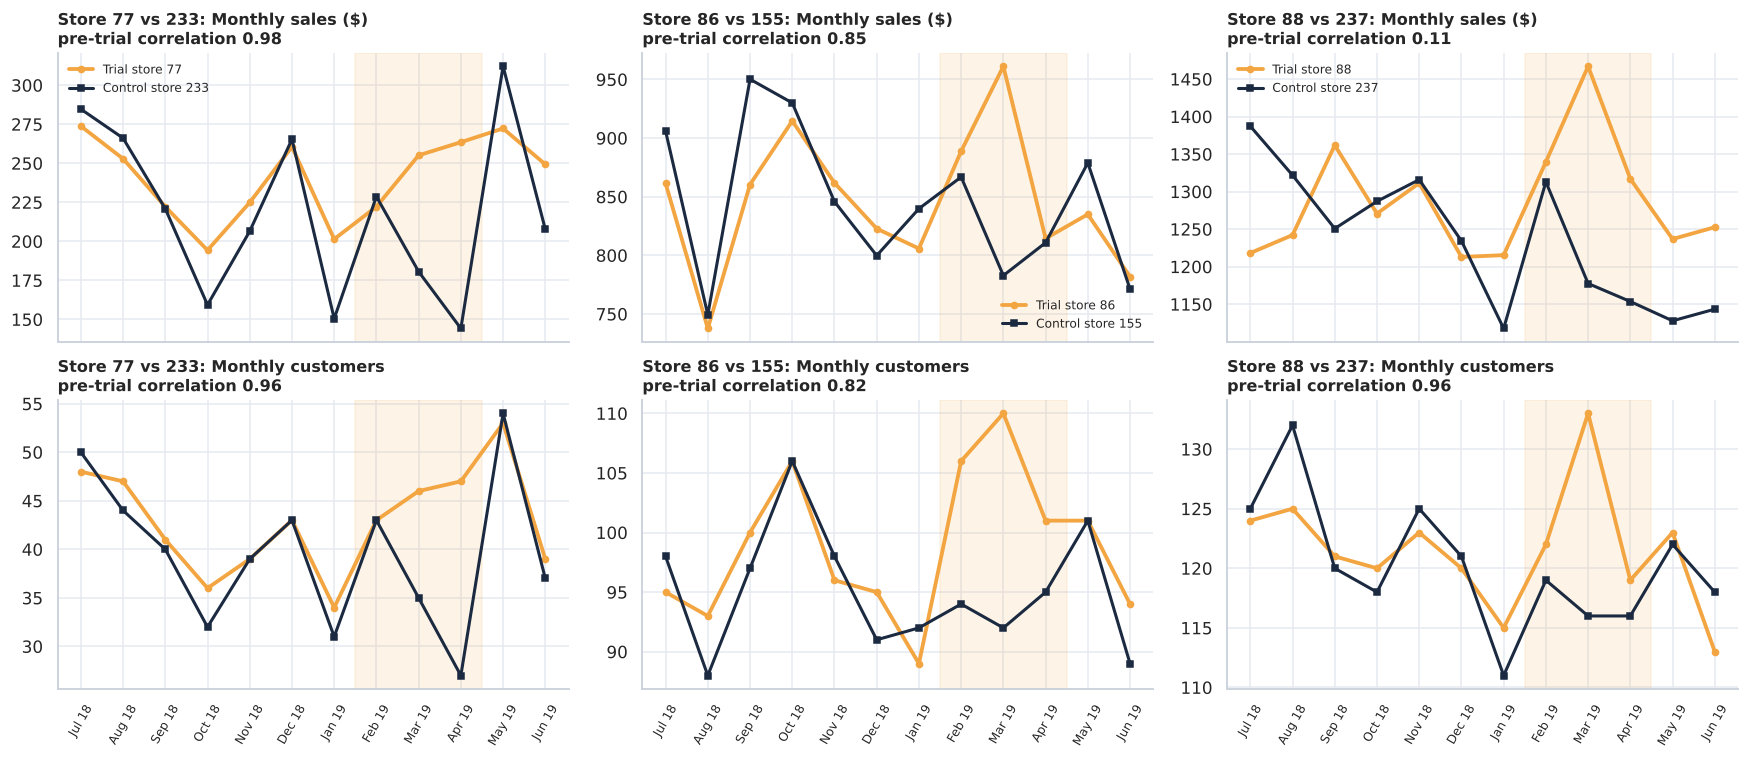

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
lab = pd.to_datetime(pd.Series(sorted(sm.MONTH.unique()))).dt.strftime("%b %y")
for j, t in enumerate(TRIAL_STORES):
    c = CONTROL[t]
    for i, (m, ttl) in enumerate([("sales", "Monthly sales ($)"), ("customers", "Monthly customers")]):
        ax = axes[i, j]; piv = sm.pivot(index="MONTH", columns="STORE_NBR", values=m)
        ax.plot(range(12), piv[t], color=AMBER, lw=2.5, marker="o", ms=4, label=f"Trial store {t}")
        ax.plot(range(12), piv[c], color=NAVY, lw=2, marker="s", ms=4, label=f"Control store {c}")
        ax.axvspan(6.5, 9.5, color=AMBER, alpha=.12); ax.set_xticks(range(12)); ax.set_xticklabels(lab, rotation=60, fontsize=8)
        corr = piv.loc[PRE_START:PRE_END, t].corr(piv.loc[PRE_START:PRE_END, c])
        ax.set_title(f"Store {t} vs {c}: {ttl}\npre-trial correlation {corr:.2f}", fontsize=10.5)
        if i == 0: ax.legend(frameon=False, fontsize=8, loc="best")
plt.tight_layout(); save(fig, "09_trial_vs_control_prelook"); plt.show()

**Controls chosen and why**
- **Store 77 -> 233 (score 0.99).** Excellent on every dimension: pre-trial correlation 0.98 (sales), 0.96 (customers), 0.97 (transactions), and essentially identical size.
- **Store 86 -> 155 (score 0.89).** Closest in size on all three metrics; correlation 0.85 / 0.82 / 0.67. Good.
- **Store 88 -> 237 (score 0.77). A weaker match, flagged.** It matches store 88 almost exactly on customer count (correlation 0.96) and size, but its **sales correlation is only 0.11**. Store 88's pre-trial sales are nearly flat, which makes correlation unstable. Other top-5 candidates have higher sales correlation (0.40-0.77) but are clearly worse on customer correlation (0.17-0.66) and size. I keep 237 per the pre-set method and test sensitivity to this choice in 2.3.

## 2.2 Trial vs control: the statistical test
1. **Scale** the control store's metric so its pre-trial total equals the trial store's (removes size differences).
2. Compute the **% gap** between trial store and scaled control every month. In the 7 pre-trial months this gap shows the normal noise (mean and standard deviation).
3. For each trial month, compute a **t-statistic** = (trial-month gap - pre-trial mean gap) / pre-trial standard deviation, with 6 degrees of freedom. A month is *significant* if its two-sided p-value < 0.05 (|t| > 2.447).
4. As a whole-period check, a **Welch t-test (SciPy)** compares the 3 trial-month gaps to the 7 pre-trial gaps. This is conservative, because only 3 months are available.

In [22]:
pre_months = [m for m in sorted(sm.MONTH.unique()) if PRE_START <= m <= PRE_END]
trial_months = [m for m in sorted(sm.MONTH.unique()) if TRIAL_START <= m <= TRIAL_END]
T_CRIT = stats.t.ppf(0.975, df=len(pre_months) - 1)      # two-sided 95% critical value, df = 7 pre-months - 1 = 6

def analyse(trial, ctrl, metric):
    piv = sm.pivot(index="MONTH", columns="STORE_NBR", values=metric)
    scale = piv.loc[pre_months, trial].sum() / piv.loc[pre_months, ctrl].sum()    # scale control to the trial store's pre-trial size
    ctrl_scaled = piv[ctrl] * scale
    pct = (piv[trial] - ctrl_scaled) / ctrl_scaled                                  # % gap, trial vs scaled control
    mu, sd = pct[pre_months].mean(), pct[pre_months].std(ddof=1)                   # what 'normal' month-to-month noise looks like
    t_month = (pct[trial_months] - mu) / sd
    p_month = 2 * stats.t.sf(np.abs(t_month), df=len(pre_months) - 1)
    welch = stats.ttest_ind(pct[trial_months], pct[pre_months], equal_var=False)   # whole-period check (conservative: only 3 trial months)
    ci = welch.confidence_interval()
    ts, cs = piv.loc[trial_months, trial].sum(), ctrl_scaled[trial_months].sum()
    return dict(trial=trial, control=ctrl, metric=metric, scale=scale, pre_corr=piv.loc[pre_months, trial].corr(piv.loc[pre_months, ctrl]),
                pre_mean_gap=mu, pre_sd_gap=sd, trial_mean_gap=pct[trial_months].mean(), lift_pct=ts / cs - 1,
                trial_total=ts, control_scaled_total=cs, abs_lift=ts - cs, t_by_month=dict(zip(trial_months, t_month.round(2))),
                p_by_month=dict(zip(trial_months, p_month.round(4))), months_sig_up=int(((p_month < 0.05) & (t_month > 0)).sum()),
                welch_t=welch.statistic, welch_p=welch.pvalue, ci_low=ci.low, ci_high=ci.high,
                pct=pct, ctrl_scaled=ctrl_scaled, piv_trial=piv[trial])

res = {(t, m): analyse(t, CONTROL[t], m) for t in TRIAL_STORES for m in ["sales", "customers"]}
for r in res.values(): r["months_detail"] = {m: (r["t_by_month"][m], r["p_by_month"][m]) for m in trial_months}
print(f"Critical t (two-sided 95%, df=6) = {T_CRIT:.3f}; a trial month is 'significant' when its gap is beyond normal pre-trial noise.\n")
for (t, m), r in res.items():
    print(f"Store {t} vs {r['control']} | {m:9s} | pre-trial gap {r['pre_mean_gap']:+.1%} (sd {r['pre_sd_gap']:.1%}) | trial-period lift {r['lift_pct']:+.1%} (${r['abs_lift']:,.0f}) "
          f"| month p-values {[float(x) for x in r['p_by_month'].values()]} | sig. months {r['months_sig_up']}/3 | whole-period Welch p={r['welch_p']:.3f}")

Critical t (two-sided 95%, df=6) = 2.447; a trial month is 'significant' when its gap is beyond normal pre-trial noise.

Store 77 vs 233 | sales     | pre-trial gap +2.7% (sd 14.1%) | trial-period lift +27.5% ($160) | month p-values [0.4998, 0.0652, 0.0023] | sig. months 1/3 | whole-period Welch p=0.317
Store 77 vs 233 | customers | pre-trial gap +0.7% (sd 5.7%) | trial-period lift +25.5% ($28) | month p-values [0.532, 0.0035, 0.0] | sig. months 2/3 | whole-period Welch p=0.282
Store 86 vs 155 | sales     | pre-trial gap +0.2% (sd 4.3%) | trial-period lift +11.2% ($268) | month p-values [0.2844, 0.001, 0.5231] | sig. months 1/3 | whole-period Welch p=0.260
Store 86 vs 155 | customers | pre-trial gap +0.1% (sd 3.7%) | trial-period lift +12.1% ($34) | month p-values [0.0171, 0.0022, 0.1788] | sig. months 2/3 | whole-period Welch p=0.071
Store 88 vs 237 | sales     | pre-trial gap +0.4% (sd 7.6%) | trial-period lift +14.2% ($513) | month p-values [0.7435, 0.0159, 0.0991] | sig. months 1/3

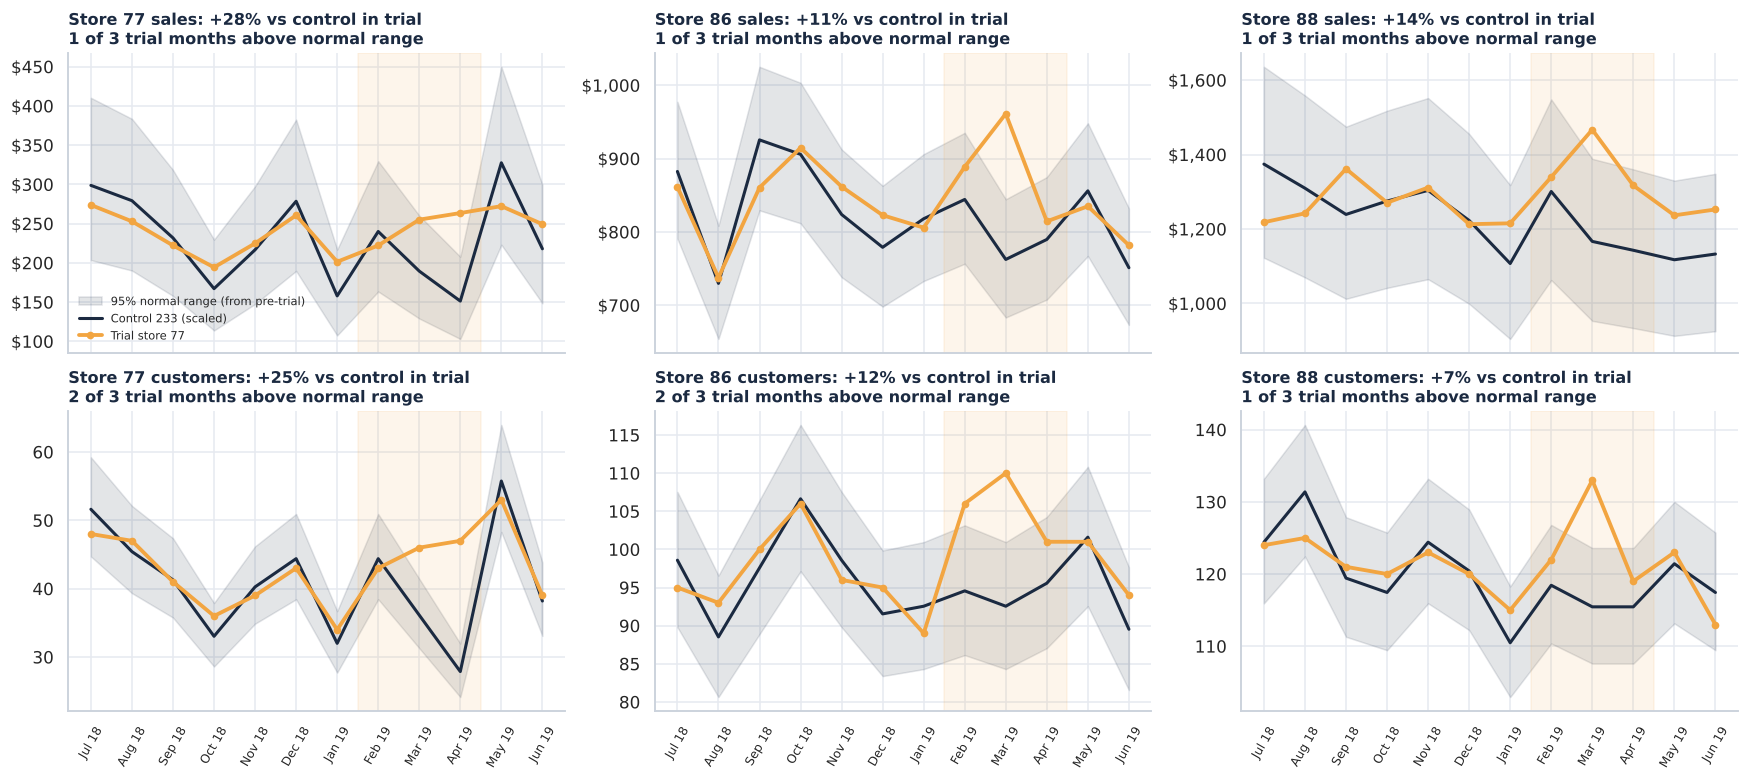

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7.2), sharex=True)
for i, m in enumerate(["sales", "customers"]):
    for j, t in enumerate(TRIAL_STORES):
        r = res[(t, m)]; ax = axes[i, j]; x = range(12); cs = r["ctrl_scaled"].values
        lo, hi = cs * (1 + r["pre_mean_gap"] - T_CRIT * r["pre_sd_gap"]), cs * (1 + r["pre_mean_gap"] + T_CRIT * r["pre_sd_gap"])
        ax.fill_between(x, lo, hi, color=NAVY, alpha=.12, label="95% normal range (from pre-trial)")
        ax.plot(x, cs, color=NAVY, lw=2, label=f"Control {r['control']} (scaled)")
        ax.plot(x, r["piv_trial"].values, color=AMBER, lw=2.5, marker="o", ms=4, label=f"Trial store {t}")
        ax.axvspan(6.5, 9.5, color=AMBER, alpha=.10)
        ax.set_xticks(x); ax.set_xticklabels(lab, rotation=60, fontsize=8)
        ax.set_title(f"Store {t} {m}: {r['lift_pct']:+.0%} vs control in trial\n{r['months_sig_up']} of 3 trial months above normal range", fontsize=10.5, color=NAVY)
        if m == "sales": ax.yaxis.set_major_formatter(dollar)
        if i == 0 and j == 0: ax.legend(frameon=False, fontsize=7.5, loc="lower left")
plt.tight_layout(); save(fig, "10_trial_results"); plt.show()

**Reading the chart:** the shaded grey band is the range the trial store should stay inside if nothing had changed (control +/- normal noise). Trial lines poking above the band during the amber window are candidate effects.

**What we found:** averaged over the trial window the trial store is above its control in all six panels, but it leaves the band in only some months, and in stores 86 and 88 the line is back inside the band by April.

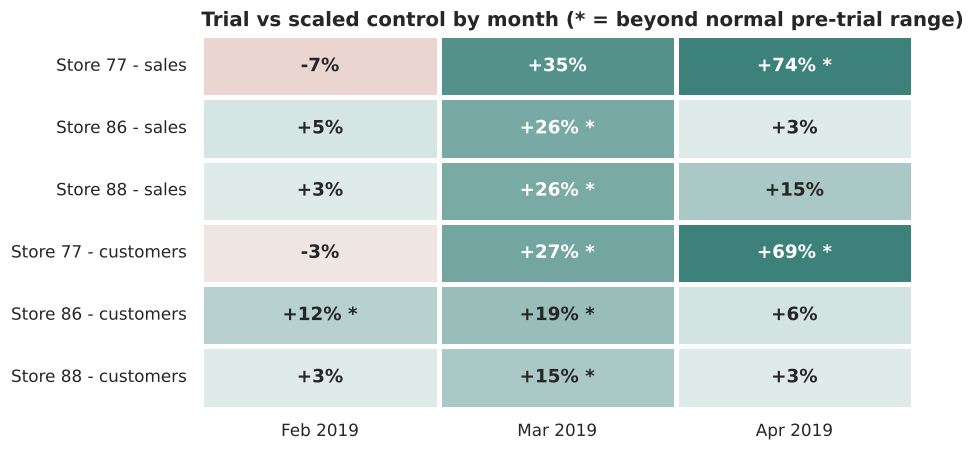

In [24]:
rows, ann = [], []
for m in ["sales", "customers"]:
    for t in TRIAL_STORES:
        r = res[(t, m)]; rows.append(pd.Series([r["pct"][mo] for mo in trial_months], index=pd.to_datetime(trial_months).strftime("%b %Y"), name=f"Store {t} - {m}"))
        ann.append([f"{r['pct'][mo]:+.0%}" + (" *" if (r["p_by_month"][mo] < 0.05 and r["t_by_month"][mo] > 0) else "") for mo in trial_months])
H = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
sns.heatmap(H, annot=np.array(ann), fmt="", cmap=sns.diverging_palette(20, 180, as_cmap=True), center=0, vmin=-.4, vmax=.4, cbar=False, linewidths=2, linecolor="white", ax=ax, annot_kws={"fontsize": 12, "fontweight": "bold"})
ax.set_title("Trial vs scaled control by month (* = beyond normal pre-trial range)"); ax.set_ylabel(""); ax.set_xlabel(""); ax.tick_params(axis="y", rotation=0)
plt.tight_layout(); save(fig, "11_monthly_gap_heatmap"); plt.show()

**What we found (sales):**
- **Store 77:** +35% in March (p = 0.065, just short), **+74% in April (p = 0.002)**.
- **Store 86:** **+26% in March (p = 0.001)**, but only +5% in February and +3% in April.
- **Store 88:** **+26% in March (p = 0.016)**, +3% in February, +15% in April (p = 0.099).

**Customers:** 77 is significant in March and April; 86 in February and March; 88 in March only.

**So what:** March is the strongest month in every store (significant for sales at 86 and 88, and for customers at all three), yet the effect fades afterwards in 86 and 88. A real layout benefit should persist, so this pattern raises the question of whether something else (a promotion, a local event) happened in March. Store 77's April surge needs caution: the control store's customers dipped sharply that month (see 2.5), so part of the "lift" is the control falling.

## 2.3 Stress-testing the result
A significance test on 3 months and 7 baseline months is fragile. Two checks:
- **Sensitivity:** if I use the 2nd or 3rd best control instead, does the conclusion hold?
- **Placebo test:** apply *exactly the same pipeline* to 60 randomly chosen stores where **no layout change happened**. How often does it declare "significant" by chance? This calibrates how much to trust a significant month.

lift_pct       months_sig_up      
metric                     customers sales     customers sales
trial control_rank control                                    
77    1            233          0.25  0.28          2.00  1.00
      2            41          -0.03 -0.12          0.00  0.00
      3            254          0.40  0.31          2.00  2.00
86    1            155          0.12  0.11          2.00  1.00
      2            114          0.13  0.12          2.00  1.00
      3            138          0.10  0.12          1.00  1.00
88    1            237          0.07  0.14          1.00  1.00
      2            123          0.03  0.11          0.00  0.00
      3            7            0.07  0.09          1.00  0.00

Placebo stores (no layout change made): 60
  [sales] >=1 of 3 months 'significantly up' by chance: 23% | >=2 of 3: 2% | whole-period p<0.05: 18% | median lift -4.9% | 90th pct +10.2%
        trial store 77: lift +27.5% exceeds 98% of placebo stores
        trial store 86: lift +11.2% exceeds 90% of placebo stores
        trial store 88: lift +14.2% exceeds 92% of placebo stores
  [customers] >=1 of 3 months 'significantly up' by chance: 27% | >=2 of 3: 7% | whole-period p<0.05: 18% | median lift -4.5% | 90th pct +12.6%
        trial store 77: lift +25.5% exceeds 98% of placebo stores
        trial store 86: lift +12.1% exceeds 88% of placebo stores
        trial store 88: lift +7.1% exceeds 78% of placebo stores


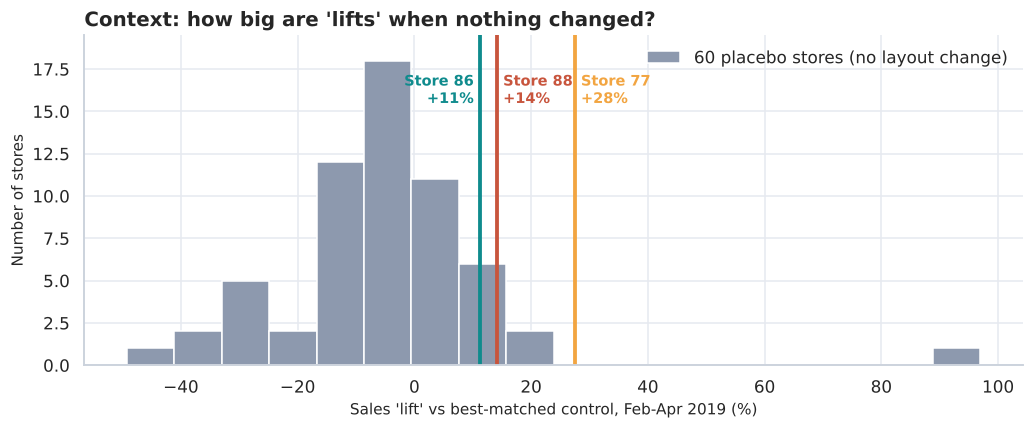

In [25]:
# ---- (a) Sensitivity: do conclusions change if we use the 2nd or 3rd best control store? ----
rows = []
for t in TRIAL_STORES:
    for rank, c in enumerate(scores[t].index[:3], 1):
        for m in ["sales", "customers"]:
            r = analyse(t, int(c), m)
            rows.append({"trial": t, "control_rank": rank, "control": int(c), "metric": m, "pre_corr": r["pre_corr"], "lift_pct": r["lift_pct"], "months_sig_up": r["months_sig_up"], "welch_p": r["welch_p"]})
sens = pd.DataFrame(rows); RESULTS["sensitivity"] = sens.to_dict("records")
display(sens.pivot_table(index=["trial", "control_rank", "control"], columns="metric", values=["lift_pct", "months_sig_up"]).round(2))

# ---- (b) Placebo test: run the identical pipeline on 60 NON-trial stores (no layout change happened there).
#          How often does 'significance' show up purely by chance in Feb-Apr 2019? ----
rng = np.random.default_rng(42)
placebo = rng.choice(candidates, 60, replace=False)
pl_rows = []
for p in placebo:
    ctrl = int(score_candidates(int(p), [s for s in candidates if s != p]).index[0])
    for m in ["sales", "customers"]:
        r = analyse(int(p), ctrl, m)
        pl_rows.append({"store": int(p), "control": ctrl, "metric": m, "lift_pct": r["lift_pct"], "months_sig_up": r["months_sig_up"], "welch_p": r["welch_p"]})
plall = pd.DataFrame(pl_rows); pl = plall[plall.metric == "sales"]
RESULTS["placebo"] = {"n": int(plall.store.nunique())}
print(f"Placebo stores (no layout change made): {plall.store.nunique()}")
for m in ["sales", "customers"]:
    d = plall[plall.metric == m]
    out = {"fp_any": float((d.months_sig_up >= 1).mean()), "fp_two": float((d.months_sig_up >= 2).mean()), "fp_welch": float((d.welch_p < .05).mean()),
           "median_lift": float(d.lift_pct.median()), "p90_lift": float(d.lift_pct.quantile(.9)),
           "pctile_of_trial": {str(t): float((d.lift_pct < res[(t, m)]["lift_pct"]).mean()) for t in TRIAL_STORES}}
    RESULTS["placebo"][m] = out
    print(f"  [{m}] >=1 of 3 months 'significantly up' by chance: {out['fp_any']:.0%} | >=2 of 3: {out['fp_two']:.0%} | whole-period p<0.05: {out['fp_welch']:.0%} | median lift {out['median_lift']:+.1%} | 90th pct {out['p90_lift']:+.1%}")
    for t in TRIAL_STORES: print(f"        trial store {t}: lift {res[(t, m)]['lift_pct']:+.1%} exceeds {out['pctile_of_trial'][str(t)]:.0%} of placebo stores")
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.hist(pl.lift_pct * 100, bins=18, color=GREY, edgecolor="white", label="60 placebo stores (no layout change)")
for t, col, ha in zip(TRIAL_STORES, [AMBER, TEAL, RED], ["left", "right", "left"]):
    v = res[(t, "sales")]["lift_pct"] * 100; ax.axvline(v, color=col, lw=2.5)
    ax.text(v + (1 if ha == "left" else -1), 15.5, f"Store {t}\n{v:+.0f}%", color=col, fontweight="bold", fontsize=9.5, ha=ha)
ax.set_ylim(0, 19.5); ax.set_xlabel("Sales 'lift' vs best-matched control, Feb-Apr 2019 (%)"); ax.set_ylabel("Number of stores")
ax.set_title("Context: how big are 'lifts' when nothing changed?"); ax.legend(frameon=False, loc="upper right")
plt.tight_layout(); save(fig, "12_placebo"); plt.show()

**Sensitivity**
- **Store 86 is the most robust:** sales +11% to +12% and customers +10% to +13% whichever of the three best controls is used.
- **Store 88** is positive with all three controls (sales +9% to +14%) but never more than 1 significant month.
- **Store 77 is fragile:** +28% with control 233, **-12% with control 41**, +31% with control 254. The sign depends on which control is chosen. It is also a tiny store (~$233 a month in sales), so a few customers swing the percentage.

**Placebo (60 untouched stores)**
- **23% show at least one "significantly higher" sales month by chance** (27% for customers), far above the 5% a textbook reading would suggest, so a single significant month is weak evidence. Seeing 2+ months is much rarer (2% for sales, 7% for customers).
- Whole-period test: 18% of untouched stores get p < 0.05.
- On size alone, trial-store sales lifts beat **98% (store 77), 90% (86) and 92% (88)** of untouched stores' apparent lifts; for customers, 98%, 88%, 78%.

**So what:** the direction is consistently positive and bigger than most untouched stores' random drift, which is encouraging. But none of it clears the bar for certainty. The most convincing signal is **customer traffic at stores 77 and 86** (2 of 3 months).

## 2.4 Why did sales move? Decomposing the drivers
Net effect = (trial store's change vs its own pre-trial baseline) minus (control's change). Positive = trial outperformed.

In [26]:
# WHY did sales move? For each driver, compare the change vs the store's OWN pre-trial baseline, trial store vs its control.
rows = []
base = lambda s, mo, m: sm[(sm.STORE_NBR == s) & sm.MONTH.isin(mo)][m].mean()
for t in TRIAL_STORES:
    c = CONTROL[t]
    for m, nm in [("customers", "Customers per month"), ("txn_per_cust", "Transactions per customer"), ("units_per_txn", "Packs per transaction"), ("price_per_pack", "Price per pack")]:
        chg_t = base(t, trial_months, m) / base(t, pre_months, m) - 1
        chg_c = base(c, trial_months, m) / base(c, pre_months, m) - 1
        rows.append({"Trial store": t, "Control": c, "Driver": nm, "Trial store change": chg_t, "Control change": chg_c, "Net effect (pp)": chg_t - chg_c})
drv = pd.DataFrame(rows)
RESULTS["drivers"] = drv.to_dict("records")
drv.pivot(index="Driver", columns="Trial store", values="Net effect (pp)").style.format("{:+.1%}")

Trial store,77,86,88
Driver,,,
Customers per month,+22.4%,+11.9%,+6.8%
Packs per transaction,+8.2%,-0.5%,-1.3%
Price per pack,-6.0%,-0.1%,+0.8%
Transactions per customer,-1.7%,-0.3%,+7.0%


**What we found:** in all three stores the gain came from **more customers**: +22 pts (77), +12 pts (86), +7 pts (88). Basket size and price per pack barely moved in 86; in 88 frequency per customer was up 7 pts; 77's price per pack fell 6 pts.

**Caution:** for store 77 the trial store's customers rose 10% against its own baseline *while the control's fell 12%*; roughly half the apparent traffic lift is the control dipping, not the trial store rising. For store 86 the picture is cleaner (+9.7% vs -2.1%).

**So what:** if the layout works, it works by drawing more shoppers in, not by lifting the basket. Success should be judged on traffic as well as sales.

## 2.5 Stage 2 verdict

| Question | Answer |
|---|---|
| Did trial stores beat their controls? | **Yes, in all three** (sales +27.5% / +11.2% / +14.2%; +$160 / +$268 / +$513 over three months, **+$941 in total**). |
| Is that statistically significant? | **Not conclusively.** 1 of 3 sales months significant per store; whole-period p = 0.32 / 0.26 / 0.15. Customer traffic is stronger (2 of 3 months at 77 and 86) but still above the 5% line over the whole period (p = 0.28 / 0.07 / 0.22). |
| Could it be noise? | **Plausibly, in part.** 23% of untouched stores show a "significant" month by chance. Effects faded by April in 86 and 88; store 77's result depends on the control chosen. |
| Best-supported store? | **Store 86:** consistent across all controls, clean control, customer-led. |
| Business size of the effect | **Small in dollars** (+$941 over 3 months across 3 stores). The commercial case needs a larger, longer trial. |

**Verdict: promising, not proven. Observed improvement, not statistically significant improvement.**

*Methodological limitations:* 3 trial months and 7 baseline months give low power; trial/control months are treated as independent; stores were chosen as trial stores (not randomised); no promotion, price or local-event data to rule out confounders; multiple comparisons (6 tests x 3 months) inflate false positives; the p-values should be read together with the placebo benchmark, not alone.

In [27]:
store_rows = []
for (t, m), r in res.items():
    store_rows.append({"trial_store": t, "control_store": r["control"], "metric": m, "pre_trial_correlation": r["pre_corr"], "scaling_factor": r["scale"],
                       "trial_period_actual": r["trial_total"], "trial_period_control_scaled": r["control_scaled_total"], "absolute_difference": r["abs_lift"],
                       "pct_difference": r["lift_pct"], "pre_trial_mean_gap": r["pre_mean_gap"], "pre_trial_sd_gap": r["pre_sd_gap"], "trial_mean_gap": r["trial_mean_gap"],
                       "months_significant_up_of_3": r["months_sig_up"], "welch_t": r["welch_t"], "welch_p_value": r["welch_p"], "ci95_low": r["ci_low"], "ci95_high": r["ci_high"],
                       **{f"t_{k}": v[0] for k, v in r["months_detail"].items()}, **{f"p_{k}": v[1] for k, v in r["months_detail"].items()}})
store_results = pd.DataFrame(store_rows); store_results.to_csv(PROC / "store_trial_results.csv", index=False)
RESULTS["store_results"] = store_results.to_dict("records"); RESULTS["t_crit"] = float(T_CRIT)
RESULTS["trial_months"] = trial_months; RESULTS["pre_months"] = pre_months
RESULTS["monthly_trial_detail"] = [{"trial": t, "control": CONTROL[t], "metric": m, "month": mo, "trial_value": float(res[(t, m)]["piv_trial"][mo]),
                                    "control_scaled": float(res[(t, m)]["ctrl_scaled"][mo]), "pct_gap": float(res[(t, m)]["pct"][mo])}
                                   for (t, m) in res for mo in sorted(sm.MONTH.unique())]
seg.to_csv(PROC / "segment_analysis.csv", index=False); prod.to_csv(PROC / "product_performance.csv", index=False)
RESULTS["cleaning_log"] = clean_log
RESULTS["row_counts"] = {"raw_transactions": len(tx), "clean_transactions": len(data), "customers_file": len(cust)}
with open(PROC / "results.json", "w") as f: json.dump(RESULTS, f, default=lambda o: o.item() if hasattr(o, "item") else str(o), indent=1)
print("Saved: results.json, segment_analysis.csv, product_performance.csv, store_trial_results.csv, QVI_clean_merged.csv")

Saved: results.json, segment_analysis.csv, product_performance.csv, store_trial_results.csv, QVI_clean_merged.csv


<a id="3"></a>
# 3. Stage 3: Conclusions, recommendations and limitations

## Recommendations for the Category Manager
1. **Grow frequency in Mainstream Young Singles/Couples** (7,930 customers, 4.6 packs each): premium-brand sharing packs (Kettle, Doritos, Tyrrells; 270-380g) and occasion promotions. Illustrative value of +1 pack per customer: **$32K (1.8% of sales)**.
2. **Protect families** (35% of sales): guarantee availability and value pricing on large packs.
3. **Prioritise large and premium formats in ranging**: the revenue leaders are 330-380g bags and Kettle, while volume per SKU is flat.
4. **Do not roll out the new layout chain-wide yet.** Run a larger second trial: 10+ stores, **6+ months**, matched control pairs fixed *before* the trial, success defined in advance on **customer traffic and sales**, and a post-trial check that the lift persists. Use **store 86 as the lead candidate** to expand first.

## Limitations (facts about the analysis, not assumptions about the business)
- Revenue only: no margin, cost or promotion data. A layout lift could still be unprofitable.
- Twelve months of data: no year-on-year comparison, so seasonality is inferred from a single year.
- Loyalty-card data only: non-loyalty sales and customers are not represented.
- Trial design assumptions (A1) come from the brief, not from the data files.
- Store 88's control has weak sales correlation; store 77 is very small and control-dependent.

## Next steps
Confirm the trial design with the client; obtain promotion and price calendars for Feb-Apr 2019; extend the test; repeat this analysis with margin when available.